# FGM with rational momentum: discovery and paper-aligned verification

Let $f$ be convex and $L$-smooth, $L>0$, let $x_\star$ minimize $f$, and
assume $\|x_0-x_\star\|\leq R$ with $R\geq0$. Set $\theta_k=(k+2)/2$. For an integer $N\geq1$, initialize
$x_0=y_0=z_0$ and, for $0\leq k<N$, use
$$
y_{k+1}=x_k-\frac{\nabla f(x_k)}L,\qquad
z_{k+1}=z_k-\frac{k+2}{2L}\nabla f(x_k),\qquad
x_{k+1}=\frac{k+1}{k+3}y_{k+1}+\frac2{k+3}z_{k+1}.
$$
This is equivalent to $x_{k+1}=y_{k+1}+k(y_{k+1}-y_k)/(k+3)$,
the recursion used in the saved discovery code (Cell 32 checks the equivalence).
The bound is $f(y_N)-f(x_\star)\leq2LR^2/((N+2)(N+3))$.

**Cell references count code cells only, starting at 1 and excluding Markdown
cells.** They match Jupyter's `In [n]` labels after restarting the kernel and
running all code cells once in order; rerunning individual cells can change those
execution labels. Each proof code cell has a `# Cell XX` header using the same
code-cell numbering as the paper and the verification index below.

Blocks 1-4 replay the selected numerical certificate and its sample-dependent
partial sums. The saved LDL factors are separate from the paper's analytic
matrix $\mathbf Q_k$. Block 5 verifies the paper's exact $V_k$ using its
literal coefficients and boundary cases; execute Code Cells 31-42 in order.
It uses only SymPy, performs no solver calls, and writes no files.


## Proof Statement

### Theorem in the paper's notation

For the iteration defined in the introduction, set $\tau_N=2/((N+2)(N+3))$ and
$$
D_k=2N^2+10N+4-k^2-7k,\qquad
a_k=\frac{(k+1)\{2N(N+1)(k+4)-k(k+2)(k+3)\}}{N(N+1)D_k}
\quad(0\leq k<N),
$$
with $a_{-1}=0$, $a_N=1$, and $b_k=a_k-a_{k-1}$ for $0\leq k\leq N$.
For $1\leq k<N$, define $\boldsymbol w_k\in\mathcal H^2$, $M_k\in\mathbb R^{2\times2}$, and $\boldsymbol c_k,\boldsymbol d_k\in\mathbb R^2$ by
$$
\boldsymbol w_k=\begin{bmatrix}z_k-x_\star\\x_k-x_\star\end{bmatrix},\quad
M_k=\begin{pmatrix}1&0\\2/(k+3)&(k+1)/(k+3)\end{pmatrix},\quad
\boldsymbol c_k=\begin{bmatrix}(k+2)/2\\(2k+3)/(k+3)\end{bmatrix},\quad
\boldsymbol d_k=\frac12\begin{bmatrix}2a_{k-1}/k\\a_k-(k+2)a_{k-1}/k\end{bmatrix}.
$$
For $2\leq k<N$ (and adjacent indices when needed), put
$$
\boldsymbol\xi_k=\begin{bmatrix}1-\tau_Nk(k+3)/2\\1-\tau_Nk(k+7)/4\end{bmatrix},\qquad
\boldsymbol\zeta_k=\tau_N\begin{bmatrix}
2a_{k-1}/k+1-(k+1)(k+2)/(N(N+1))\\
(k+1)(k+2)/(N(N+1))-(k+2)a_{k-1}/k
\end{bmatrix}.
$$
With $\boldsymbol e_1=(1,0)^\top$, define $\overline{\mathbf Q}_k,\mathbf Q_k\in\mathbb R^{2\times2}$ and $\boldsymbol n_k\in\mathbb R^2$ by
$$
\overline{\mathbf Q}_k=\begin{pmatrix}
0&(\boldsymbol\zeta_k)_1/(\boldsymbol\xi_k)_2\\
(\boldsymbol\zeta_k)_1/(\boldsymbol\xi_k)_2&
(\boldsymbol\zeta_k)_2/(\boldsymbol\xi_k)_2
-(\boldsymbol\zeta_k)_1(\boldsymbol\xi_k)_1/(\boldsymbol\xi_k)_2^2
\end{pmatrix},\qquad
\boldsymbol n_k=\begin{bmatrix}1\\-(\boldsymbol\xi_k)_1/(\boldsymbol\xi_k)_2\end{bmatrix},
$$
$$
\mathbf Q_k=\overline{\mathbf Q}_k+
\frac{(\boldsymbol d_{k-1})_1-
\boldsymbol e_1^\top M_{k-1}^\top\overline{\mathbf Q}_k\boldsymbol c_{k-1}}
{(\boldsymbol e_1^\top M_{k-1}^\top\boldsymbol n_k)
 (\boldsymbol n_k^\top\boldsymbol c_{k-1})}
\boldsymbol n_k\boldsymbol n_k^\top.
$$
Every denominator is nonzero on its stated domain (Cell 34).
The full potential, with $f_\star=f(x_\star)$, is
$$
\begin{aligned}
V_0={}&0,\\
V_1={}&a_1(f(x_1)-f_\star)-L\tau_N\|x_0-x_\star\|^2
+\frac{a_1}{2L}\|\nabla f(x_1)\|^2
-b_1\langle\nabla f(x_1),x_1-x_\star\rangle\\
&+\frac{L\tau_N(1-4\tau_N)}{(1-2\tau_N)^2}\|x_1-x_\star\|^2,
\qquad N\geq2,\\
V_k={}&a_k(f(x_k)-f_\star)-L\tau_N\|x_0-x_\star\|^2
+\frac{a_k}{2L}\|\nabla f(x_k)\|^2
-2\langle\nabla f(x_k),\boldsymbol d_k^\top\boldsymbol w_k\rangle
+L\boldsymbol w_k^\top \mathbf Q_k\boldsymbol w_k,
\quad2\leq k<N,\\
V_N={}&f(y_N)-f_\star-L\tau_N\|x_0-x_\star\|^2
+\frac1{2L}\|\nabla f(y_N)-Lb_N(y_N-x_\star)\|^2.
\end{aligned}
$$
The terminal expression applies at $N=1$. The vector quadratic means
$\sum_{i,j}(\mathbf Q_k)_{ij}\langle(\boldsymbol w_k)_i,(\boldsymbol w_k)_j\rangle$.
The following exact certificate proves $V_N\leq\cdots\leq V_0=0$ and hence
$f(y_N)-f_\star\leq L\tau_NR^2$.

### Decrements, square terms, and verification index

Use the paper's nonpositive interpolation residual
$$
\mathcal I_f(p,q)=f(q)-f(p)+\langle\nabla f(q),p-q\rangle
+\frac1{2L}\|\nabla f(p)-\nabla f(q)\|^2\leq0.
$$
For $N\geq2$, the identities are
$$
\begin{aligned}
V_1-V_0&=b_0\mathcal I_f(x_\star,x_0)+a_0\mathcal I_f(x_0,x_1)
+b_1\mathcal I_f(x_\star,x_1)-S_0,\\
V_{k+1}-V_k&=a_k\mathcal I_f(x_k,x_{k+1})
+b_{k+1}\mathcal I_f(x_\star,x_{k+1})-S_k,\quad1\leq k<N-1,\\
V_N-V_{N-1}&=a_{N-1}\mathcal I_f(x_{N-1},y_N)
+b_N\mathcal I_f(x_\star,y_N)-S_{N-1}.
\end{aligned}
$$
At $N=1$ the first identity uses $y_1$ in place of $x_1$ and the terminal $V_1$.
The boundary squares are
$$
S_0=\frac{L\tau_N}{(1-2\tau_N)^2}
\left\|\frac{\nabla f(x_0)}L-2\tau_N(x_0-x_\star)\right\|^2,
$$
$$
S_1=L\alpha_1\left\|\frac{\nabla f(x_1)}L-
\frac{2\tau_N}{1-2\tau_N}(x_1-x_\star)\right\|^2,\quad
\alpha_1=\frac{(N^2+5N+2)(5N^2+5N-6)}
{N(N+1)(N^2+5N-2)^2},\quad N\geq3.
$$
For $2\leq k<N$, define $s_k,t_k\in\mathcal H$ by
$$
s_k=\frac{\nabla f(x_k)}L-
\frac{2\tau_N}{(\boldsymbol\xi_k)_2}(x_k-x_\star),\qquad
t_k=\boldsymbol n_k^\top\boldsymbol w_k.
$$
For $2\leq k\leq N-2$,
$$
\alpha_k=a_k-\boldsymbol c_k^\top \mathbf Q_{k+1}\boldsymbol c_k
=\frac{a_k(D_k+8)}{2D_k},\qquad
\beta_k=(\mathbf Q_k-M_k^\top \mathbf Q_{k+1}M_k)_{11},\qquad
S_k=L\alpha_k\|s_k\|^2+L\beta_k\|t_k\|^2.
$$
For $N\geq3$,
$$
\alpha_{N-1}=1-b_N-b_N^2/2,\qquad
\beta_{N-1}=(\mathbf Q_{N-1})_{11}-\frac{a_{N-2}^2}{(N-1)^2\alpha_{N-1}},
$$
$$
S_{N-1}=L\alpha_{N-1}\left\|s_{N-1}-\frac{a_{N-2}}{(N-1)\alpha_{N-1}}t_{N-1}\right\|^2
+L\beta_{N-1}\|t_{N-1}\|^2.
$$
At $N=2$, instead $S_1=11L\|\nabla f(x_1)/L-(x_1-x_\star)/4\|^2/18$.
All coefficients used are positive, as certified in Cells 33, 34, and 35.

| Code cell (1-based) | Exact identities checked |
|---|---|
| 32 | Paper definitions, equivalence of the two algorithm forms, state transition, $z_1=x_1$ |
| 33 | $\mathbf Q_k\xi_k=\zeta_k$, preceding cross coefficient, all three transport equations, interior kernel, zero $(1,3)$ entry, two-square factorization, literal $\alpha_k$ and $\beta_k/P_{m,\ell}$ formulas and positivity |
| 34 | $D_ka_k,D_k,a_k,b_k$ identities; both denominator factorizations in the paper |
| 35 | Base scalar square identities, first-step rank-one identity and literal $\alpha_1$, terminal kernel/two-square identity, literal $p_4,p_9$ and shifted polynomials, endpoint positivity |
| 36 | Supplemental exact full-coordinate decrements at $N=1,2,3,4,6,8$ |
| 37 | Generic interior interpolation cancellation and complete first-step decrement for symbolic $N\geq3$ |
| 38 | Base decrement for symbolic $N\geq2$ |
| 39 | Terminal interpolation cancellation and complete two-square decrement for symbolic $N\geq3$ |
| 40 | $N=1$: exact weights and base identity using the terminal potential |
| 41 | $N=2$: exact weights and last decrement with coefficient $11/18$ |
| 42 | Terminal metric/radius identity and the factor $L\tau_N$ |

These symbolic checks use independent function-value atoms and formal coordinates
for arbitrary vectors. A quadratic identity is checked by extracting **every
Gram coefficient**, every function-value coefficient, and the constant. Thus the
verification applies in every dimension; it is not a numerical or one-dimensional
sample. Positivity is a separate exact polynomial argument. The interpolation
inequality and nonnegative squared norms then imply the theorem.

In [1]:
from pathlib import Path
import sys
import json
from fractions import Fraction

sys.dont_write_bytecode = True
workspace_start = Path.cwd().resolve()
notebook_candidates = [workspace_start]
for parent in (workspace_start, *workspace_start.parents):
    notebook_candidates.extend(
        [
            parent / "examples_peppy" / "fgm_rational_tight",
        ]
    )
NOTEBOOK_DIR = next(
    (
        candidate
        for candidate in notebook_candidates
        if (candidate / "fgm_rational_tight_setup.py").is_file()
    ),
    None,
)
if NOTEBOOK_DIR is None:
    raise FileNotFoundError(
        "Run from this notebook directory or a parent in the Peppy workspace."
    )
REPO_ROOT = NOTEBOOK_DIR.parents[1]
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import numpy as np  # noqa: E402 - repository path bootstrap above
import sympy as sp  # noqa: E402 - repository path bootstrap above
import matplotlib.pyplot as plt  # noqa: E402 - repository path bootstrap above
import pepflow as pf  # noqa: E402 - repository path bootstrap above

## Function class and symbolic parameters

`SmoothConvexFunction` supplies smooth-convex interpolation inequalities.
`L` is the gradient Lipschitz constant and `R` is the initial distance bound;
the PEP constraint therefore uses `R**2`.

In [2]:
L = pf.Parameter("L")
R = pf.Parameter("R")
f = pf.SmoothConvexFunction(is_basis=True, tags=["f"], L=L)

## Algorithm and PEP setup

The complete current-run setup is visible below. Rational momentum coefficients
are exact. The aliases $y_{0}=x_{0}$ and $x_{1}=y_{1}$ share their vector object, so the
function oracle is also shared. The metric is evaluated at $y_{N}$.

In [3]:
def make_ctx_fgm_rational_test(ctx_name: str, N, **kwargs) -> pf.PEPContext:
    """Encode the stated recursion with exact rational momentum coefficients."""
    if not sp.sympify(N).is_Integer or N < 1:
        raise ValueError("N must be an integer >= 1")
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x = pf.Vector(is_basis=True, tags=["y_0", "x_0"])
    y = x
    f.set_stationary_point("x_star")
    for k in range(int(N)):
        y_next = x - f.grad(x) / L
        y_next.add_tag(f"y_{k + 1}")
        # At k=0 these are the same point; preserve its oracle identity.
        x_next = y_next if k == 0 else y_next + sp.Rational(k, k + 3) * (y_next - y)
        x_next.add_tag(f"x_{k + 1}")
        x, y = x_next, y_next
    return ctx


def get_pep_setup(N, params):
    """Return the standard (context, builder, function) runner interface."""
    for name, value in params.items():
        if name == "L" and sp.sympify(value) <= 0:
            raise ValueError("L must be positive")
        if name == "R" and sp.sympify(value) < 0:
            raise ValueError("R must be nonnegative")
    ctx = make_ctx_fgm_rational_test(f"ctx_{N}", N)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(
        ((ctx["x_0"] - ctx["x_star"]) ** 2).le(R**2, name="initial_condition")
    )
    pb.set_performance_metric(f(ctx[f"y_{N}"]) - f(ctx["x_star"]))
    return ctx, pb, f

## Numerical evidence

The next cells load the saved refined sweep, print all seven objective values,
and compare them with the conjecture. They perform no new solver calls.
The refined sweep used the same full PEP with tighter CLARABEL tolerances.
Agreement here is a finite numerical check, not a proof or an exact equality claim.

In [4]:
params_numeric = {"L": sp.Integer(1), "R": sp.Integer(1)}
evidence_path = NOTEBOOK_DIR / "supplementary" / "_sweep_refined.json"
saved_sweep = json.loads(evidence_path.read_text(encoding="utf-8"))
sweep_results = saved_sweep["results"]
Ns = np.array([row["N"] for row in sweep_results], dtype=int)
pep_values = np.array([row["opt_value"] for row in sweep_results], dtype=float)
assert np.array_equal(Ns, np.arange(1, 8))
assert np.all(np.isfinite(pep_values)) and np.all(pep_values > 0)
conjecture = np.array(
    [
        float(
            2
            * params_numeric["L"]
            * params_numeric["R"] ** 2
            / ((int(n) + 2) * (int(n) + 3))
        )
        for n in Ns
    ]
)
relative_errors = np.abs(pep_values - conjecture) / conjecture
print("Current-run refined sweep: L=1, R=1; metric f(y_N)-f(x_star)")
print(" N       PEP optimum          conjecture        relative error")
for n, value, candidate, error in zip(Ns, pep_values, conjecture, relative_errors):
    print(f"{n:2d}   {value: .12f}     {candidate: .12f}     {error:.3e}")
print("\nReciprocal PEP values:", np.round(1 / pep_values, 6))
print("First differences:", np.round(np.diff(1 / pep_values), 6))
print(
    "Rational guesses (denominator <= 1000):",
    [str(Fraction(float(value)).limit_denominator(1000)) for value in pep_values],
)
np.testing.assert_allclose(pep_values, conjecture, rtol=1e-6, atol=1e-8)
print("\nFinite sweep agrees with the conjecture at rtol=1e-6, atol=1e-8.")
print("No all-horizon analytic claim is established in Block 1.")

Current-run refined sweep: L=1, R=1; metric f(y_N)-f(x_star)
 N       PEP optimum          conjecture        relative error
 1    0.166666663354      0.166666666667     1.988e-08
 2    0.099999999599      0.100000000000     4.007e-09
 3    0.066666666361      0.066666666667     4.578e-09
 4    0.047619046757      0.047619047619     1.811e-08
 5    0.035714285601      0.035714285714     3.167e-09
 6    0.027777777666      0.027777777778     4.007e-09
 7    0.022222221705      0.022222222222     2.328e-08

Reciprocal PEP values: [ 6.       10.       15.       21.       28.       36.       45.000001]
First differences: [4.       5.       6.       7.       8.       9.000001]
Rational guesses (denominator <= 1000): ['1/6', '1/10', '1/15', '1/21', '1/28', '1/36', '1/45']

Finite sweep agrees with the conjecture at rtol=1e-6, atol=1e-8.
No all-horizon analytic claim is established in Block 1.


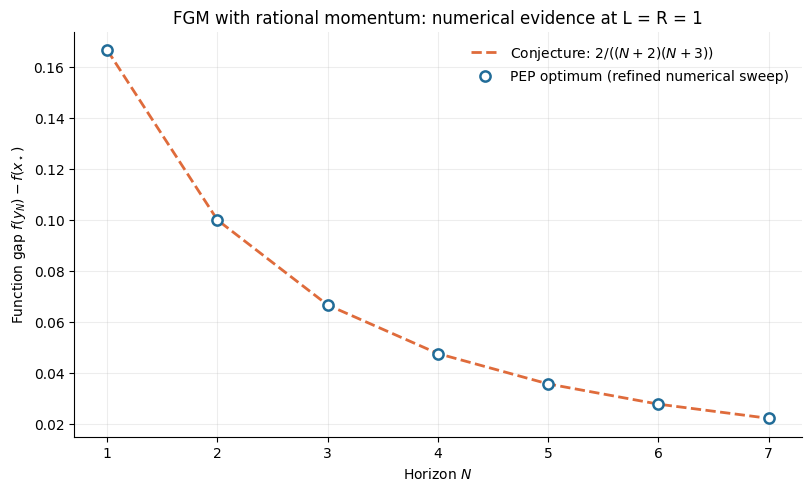

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
ax.plot(
    Ns,
    conjecture,
    "--",
    color="#df6b3b",
    linewidth=2,
    label=r"Conjecture: $2/((N+2)(N+3))$",
)
ax.scatter(
    Ns,
    pep_values,
    s=54,
    facecolors="white",
    edgecolors="#216c98",
    linewidths=1.8,
    zorder=3,
    label="PEP optimum (refined numerical sweep)",
)
ax.set(
    xlabel=r"Horizon $N$",
    ylabel=r"Function gap $f(y_N)-f(x_\star)$",
    title="FGM with rational momentum: numerical evidence at L = R = 1",
    xticks=Ns,
)
ax.grid(alpha=0.22)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
figure_path = NOTEBOOK_DIR / "supplementary" / "fgm_rational_test_rate.png"
fig.savefig(figure_path, dpi=180)
plt.show()

In the initial discovery sweep, the reciprocal values followed the candidate
quadratic pattern $1/\mathrm{PEP}_{N}\approx(N+2)(N+3)/2$ at $L=R=1$,
suggesting an $O(N^{-2})$ rate. The resulting conjecture was
$2LR^{2}/((N+2)(N+3))$ for $N\geq1$. The factor $LR^{2}$ agrees with the
smoothness and distance scaling of the PEP formulation.

Block 2 supplied a complete finite numerical certificate. Block 3 then
supplied numerical partial sums and cross-horizon rank evidence. The exact
all-horizon proof was still pending at that discovery stage; Block 5 below
now completes it.

## Block 2: dense and selected sparse certificates

This section reads the complete dense and selected certificates obtained in
this run at the saved verification horizon. The numerical multipliers,
normalization, slack matrix, and decomposition of the selected sample all
belong to one solve and one certificate ID. Executing this notebook rebuilds
the PEP and revalidates the saved certificate without invoking a solver.

The finite numerical identity is checked separately from any proposed exact
formula. Block 3 below constructs numerical partial sums. The vector basis and final all-horizon Lyapunov theorem remain pending Blocks 4 and 5.

The saved numerical certificate is a finite-horizon discovery record. Its proof
status is distinguished from the exact all-horizon identities in Block 5.

In [6]:
import hashlib
import importlib.util
from collections import defaultdict
from pepflow.constraint import ScalarConstraint, PSDConstraint
from pepflow.operator import LinearOperatorTranspose
from pepflow.utils import Comparator


STATE_DIR = NOTEBOOK_DIR / "state"
b1 = json.loads((STATE_DIR / "fgm_rational_test_b1.json").read_text(encoding="utf-8"))
dense = json.loads(
    (STATE_DIR / "fgm_rational_test_dense.json").read_text(encoding="utf-8")
)
selected = json.loads(
    (STATE_DIR / "fgm_rational_test_b2.json").read_text(encoding="utf-8")
)
relaxed = json.loads(
    (STATE_DIR / "fgm_rational_test_relaxed.json").read_text(encoding="utf-8")
)
certificate_keys = (
    "N_verify",
    "params_json",
    "relaxed_constraints",
    "S_matrix",
    "S_row_names",
    "S_col_names",
    "basis_vectors",
    "basis_scalars",
    "opt_value",
    "tau_sol",
    "tau_name",
    "named_dual_values",
    "constraint_metadata",
    "normalization",
    "certificate_provenance",
    "numerical_checks",
    "numerical_decomposition",
)
for label, data in (("dense", dense), ("selected", selected)):
    canonical = json.dumps(
        {key: data[key] for key in certificate_keys},
        sort_keys=True,
        separators=(",", ":"),
        allow_nan=False,
    )
    recomputed_id = hashlib.sha256(canonical.encode("utf-8")).hexdigest()
    assert recomputed_id == data["certificate_id"], (label, "certificate ID mismatch")
    assert data["certificate_provenance"]["pep_type"] == "primal"
    assert data["certificate_provenance"]["solver_status"] == "optimal"
    print(label, "certificate ID:", recomputed_id)
    print(
        label,
        "solver:",
        json.dumps(data["certificate_provenance"]["solver"], sort_keys=True),
    )
assert all(
    selected[key] == relaxed[key] for key in (*certificate_keys, "certificate_id")
)
assert selected["N_verify"] == dense["N_verify"]
print("Block 1 sweep/initial verification horizon:", b1["N_verify"])
assert selected["params_json"] == dense["params_json"] == b1["params_json"]
assert Path(pf.__file__).resolve() == REPO_ROOT / "pepflow" / "__init__.py"
N_verify = int(selected["N_verify"])
params = json.loads(selected["params_json"])
params_sp = {key: sp.Rational(str(value)) for key, value in params.items()}
assert params_sp["L"] > 0 and params_sp["R"] >= 0 and N_verify >= 1
candidate_bound = float(
    2 * params_sp["L"] * params_sp["R"] ** 2 / ((N_verify + 2) * (N_verify + 3))
)
print("Horizon:", N_verify, "parameters:", params)
print("Selected/relaxed certificate agreement verified.")

dense certificate ID: d582b197ad4f2e403d6ee266df35974b481f22960b5cbcb540b73f029f29ec8f
dense solver: {"api": "CVXPrimalSolver.build_problem + cvxpy.Problem.solve", "cvxpy_version": "1.7.1", "effective_name": "CLARABEL", "num_iters": 12, "settings": {"max_iter": 500, "tol_feas": 1e-08, "tol_gap_abs": 1e-08, "tol_gap_rel": 1e-08}}
selected certificate ID: ccd3b13c86fb1a98e5535046db94cb1914e2798f353b69f64ba8411e43e90bd8
selected solver: {"api": "CVXPrimalSolver.build_problem + cvxpy.Problem.solve", "cvxpy_version": "1.7.1", "effective_name": "CLARABEL", "num_iters": 11, "settings": {"max_iter": 500, "tol_feas": 1e-08, "tol_gap_abs": 1e-08, "tol_gap_rel": 1e-08}}
Block 1 sweep/initial verification horizon: 4
Horizon: 6 parameters: {'L': 1, 'R': 1}
Selected/relaxed certificate agreement verified.


In [7]:
display_threshold = 1e-7  # Presentation only: no weight is discarded in verification.
for label, data in (("dense", dense), ("selected", selected)):
    print("\n", label.upper(), "objective:", format(data["opt_value"], ".14g"))
    print(
        "Conjectured bound:",
        format(candidate_bound, ".14g"),
        "absolute difference:",
        abs(data["opt_value"] - candidate_bound),
    )
    grouped = defaultdict(list)
    for name, meta in data["constraint_metadata"].items():
        if meta["origin"] == "interpolation":
            grouped[(meta["owner"], meta["group"], meta["kind"])].append(
                (name, data["named_dual_values"][name], meta["relaxed"])
            )
    for group, values in grouped.items():
        retained = [(name, value) for name, value, dropped in values if not dropped]
        prominent = [
            (name, value)
            for name, value in retained
            if np.max(np.abs(np.asarray(value)), initial=0) > display_threshold
        ]
        print(
            "Group",
            group,
            ":",
            len(retained),
            "retained /",
            len(values),
            "total;",
            len(prominent),
            "above display threshold",
        )
        for name, value in sorted(
            prominent, key=lambda item: -np.max(np.abs(np.asarray(item[1])))
        )[:6]:
            print("  ", name, "=", value)
    S_summary = np.asarray(data["S_matrix"], dtype=float)
    spectrum = np.linalg.eigvalsh((S_summary + S_summary.T) / 2)
    print(
        "S dimension:",
        S_summary.shape,
        "numerical rank at 1e-7:",
        int(np.sum(spectrum > 1e-7)),
        "eigenvalues:",
        spectrum,
    )
    print("Original vector order:", data["basis_vectors"])
    print("Original function-value order:", data["basis_scalars"])
    print(label.upper(), "true lambda matrix (saved complete certificate):")
    pf.pprint_labeled_matrix(
        np.asarray(data["lambda_matrix"], dtype=float),
        data["lambda_row_names"],
        data["lambda_col_names"],
        precision=7,
    )
    print(label.upper(), "true S matrix (saved complete certificate):")
    pf.pprint_labeled_matrix(
        S_summary, data["S_row_names"], data["S_col_names"], precision=7
    )
dense_selected_gap = abs(dense["opt_value"] - selected["opt_value"])
assert dense_selected_gap < selected["numerical_checks"]["tolerances"]["dense_opt_atol"]
assert abs(selected["opt_value"] - candidate_bound) < 1e-5
print("\nPreserved dense objective; gap =", dense_selected_gap)
print("Selected sparsity pattern:", selected["sparsity_search"]["selected_pattern"])
print(
    "Existing support rule reused:",
    selected["sparsity_search"]["reuse_existing_support_rule"],
)
print(
    "Original support certificate:",
    selected["sparsity_search"]["source_certificate_id"],
)
assert selected["sparsity_search"]["dense_certificate_id"] == dense["certificate_id"]


 DENSE objective: 0.027777777666479
Conjectured bound: 0.027777777777778 absolute difference: 1.1129866472892047e-10
Group ('f', 'Smooth Convex Function', 'scalar') : 56 retained / 56 total; 49 above display threshold
   f:x_5,y_6 = 0.4228492433239131
   f:x_4,y_6 = 0.4089966307308646
   f:x_3,x_4 = 0.26551503670568544
   f:x_star,y_6 = 0.25047134714911284
   f:x_2,x_3 = 0.19915005525834661
   f:x_star,x_5 = 0.18472294441725565
S dimension: (9, 9) numerical rank at 1e-7: 7 eigenvalues: [5.23303142e-11 1.86358457e-10 2.56981135e-03 7.46451174e-02
 1.06049252e-01 1.47352858e-01 1.92971516e-01 2.36550838e-01
 1.59105128e+00]
Original vector order: ['x_0', 'x_star', 'grad_f(x_0)', 'grad_f(x_1)', 'grad_f(x_2)', 'grad_f(x_3)', 'grad_f(x_4)', 'grad_f(x_5)', 'grad_f(y_6)']
Original function-value order: ['f(x_star)', 'f(x_0)', 'f(x_1)', 'f(x_2)', 'f(x_3)', 'f(x_4)', 'f(x_5)', 'f(y_6)']
DENSE true lambda matrix (saved complete certificate):


<IPython.core.display.Math object>

DENSE true S matrix (saved complete certificate):


<IPython.core.display.Math object>


 SELECTED objective: 0.027777777625429
Conjectured bound: 0.027777777777778 absolute difference: 1.5234843941946963e-10
Group ('f', 'Smooth Convex Function', 'scalar') : 13 retained / 56 total; 13 above display threshold
   f:x_5,y_6 = 0.8947462900351554
   f:x_4,x_5 = 0.6521786447179236
   f:x_3,x_4 = 0.4474395556985822
   f:x_2,x_3 = 0.2808699057223548
   f:x_star,x_5 = 0.24256764552501595
   f:x_star,x_4 = 0.20473908923885367
S dimension: (9, 9) numerical rank at 1e-7: 7 eigenvalues: [3.26044426e-11 2.46470942e-10 3.05462184e-02 8.52445739e-02
 1.58666706e-01 2.52681766e-01 3.69208842e-01 5.17646562e-01
 1.62740026e+00]
Original vector order: ['x_0', 'x_star', 'grad_f(x_0)', 'grad_f(x_1)', 'grad_f(x_2)', 'grad_f(x_3)', 'grad_f(x_4)', 'grad_f(x_5)', 'grad_f(y_6)']
Original function-value order: ['f(x_star)', 'f(x_0)', 'f(x_1)', 'f(x_2)', 'f(x_3)', 'f(x_4)', 'f(x_5)', 'f(y_6)']
SELECTED true lambda matrix (saved complete certificate):


<IPython.core.display.Math object>

SELECTED true S matrix (saved complete certificate):


<IPython.core.display.Math object>


Preserved dense objective; gap = 4.1049774690549157e-11
Selected sparsity pattern: forward_chain_plus_star
Existing support rule reused: True
Original support certificate: aa7bee0066d5762595ffba71ee0f83ff698153bdc243e3713ce8224a896a19e1


### Relaxation and complete constraint inventory

The retained interpolation pattern is constructed explicitly below from the
current setup. Each omitted inequality is recorded by its exact name. A new
builder applies that list once; it is used to check coordinates and constraint
metadata, with no fresh optimization. The saved dense solve and selected solve
are compared above, while only the selected solve supplies the proof weights.

In [8]:
setup_file = NOTEBOOK_DIR / "fgm_rational_tight_setup.py"
spec = importlib.util.spec_from_file_location("_fgm_rational_b2_notebook", setup_file)
assert spec is not None and spec.loader is not None
setup_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(setup_module)
ctx, pb, obj = setup_module.get_pep_setup(sp.Integer(N_verify), params_sp)
assert pb.ctx is ctx
ctx.set_as_current()

# The explicit selected pattern is inserted here by the updater from its
# current-run construction; no solver call occurs in this notebook.
points = [f"x_{i}" for i in range(N_verify)] + [
    "x_1" if N_verify == 1 else f"y_{N_verify}"
]
retained_pairs = {(points[i], points[i + 1]) for i in range(N_verify)}
retained_pairs.update(("x_star", point) for point in points)
constructed_relaxation = [
    c.name
    for c in obj.get_interpolation_constraints(ctx)
    if tuple(c.name.split(":", 1)[1].split(",")) not in retained_pairs
]
print("Retained interpolation pairs:", sorted(retained_pairs))
assert sorted(constructed_relaxation) == sorted(selected["relaxed_constraints"])
pb.set_relaxed_constraints(constructed_relaxation)
print("Dropped", len(constructed_relaxation), "constraints:")
print(json.dumps(constructed_relaxation, indent=2))

entries = [(c, "initial", None, None) for c in pb.init_conditions]
for owner in [*ctx.func_to_triplets, *ctx.oper_to_duplets]:
    if isinstance(owner, LinearOperatorTranspose):
        continue
    groups = ctx.get_constraint_data(owner)
    entries.extend(
        (c, "interpolation", str(owner), str(group))
        for group, constraints in groups.sc_dict.items()
        for c in constraints
    )
    entries.extend(
        (c, "interpolation", str(owner), str(group))
        for group, c in groups.psd_dict.items()
    )
assert len({c.name for c, *_ in entries}) == len(entries)
metadata = {}
for c, origin, owner, group in entries:
    is_scalar = isinstance(c, ScalarConstraint)
    assert is_scalar or isinstance(c, PSDConstraint), c.name
    metadata[c.name] = dict(
        origin=origin,
        owner=owner,
        group=group,
        kind="scalar" if is_scalar else "psd",
        comparator=c.cmp.value,
        shape=[] if is_scalar else list(np.asarray(c.lhs - c.rhs).shape),
        relaxed=c.name in pb.relaxed_constraints,
    )
assert metadata == selected["constraint_metadata"]
assert set(metadata) == set(selected["named_dual_values"])
assert set(pb.relaxed_constraints).issubset(metadata)
basis = ctx.basis_vectors()
basis_labels = [str(v) for v in basis]
scalar_labels = [str(v) for v in ctx.basis_scalars()]
assert (
    basis_labels
    == selected["basis_vectors"]
    == selected["S_row_names"]
    == selected["S_col_names"]
)
assert scalar_labels == selected["basis_scalars"]
pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
normalization = selected["normalization"]
tau_name = selected["tau_name"]
assert tau_name in {c.name for c in pb.init_conditions}
assert metadata[tau_name]["kind"] == "scalar" and not metadata[tau_name]["relaxed"]
assert selected["named_dual_values"][tau_name] == selected["tau_sol"]
assert normalization["tau_name"] == tau_name
assert normalization["bound_value"] == selected["opt_value"]
assert normalization["initial_condition"] == b1["initial_condition"]
assert normalization["performance_metric"] == b1["performance_metric"]
assert normalization["bound_formula"] == b1["conjectured_rate"]
print("Complete inventory:", len(entries), "constraints; exact saved metadata match.")
print("Normalization:", normalization)
print("Coordinate order verified.")

Retained interpolation pairs: [('x_0', 'x_1'), ('x_1', 'x_2'), ('x_2', 'x_3'), ('x_3', 'x_4'), ('x_4', 'x_5'), ('x_5', 'y_6'), ('x_star', 'x_0'), ('x_star', 'x_1'), ('x_star', 'x_2'), ('x_star', 'x_3'), ('x_star', 'x_4'), ('x_star', 'x_5'), ('x_star', 'y_6')]
Dropped 43 constraints:
[
  "f:x_0,x_star",
  "f:x_0,x_2",
  "f:x_0,x_3",
  "f:x_0,x_4",
  "f:x_0,x_5",
  "f:x_0,y_6",
  "f:x_1,x_star",
  "f:x_1,x_0",
  "f:x_1,x_3",
  "f:x_1,x_4",
  "f:x_1,x_5",
  "f:x_1,y_6",
  "f:x_2,x_star",
  "f:x_2,x_0",
  "f:x_2,x_1",
  "f:x_2,x_4",
  "f:x_2,x_5",
  "f:x_2,y_6",
  "f:x_3,x_star",
  "f:x_3,x_0",
  "f:x_3,x_1",
  "f:x_3,x_2",
  "f:x_3,x_5",
  "f:x_3,y_6",
  "f:x_4,x_star",
  "f:x_4,x_0",
  "f:x_4,x_1",
  "f:x_4,x_2",
  "f:x_4,x_3",
  "f:x_4,y_6",
  "f:x_5,x_star",
  "f:x_5,x_0",
  "f:x_5,x_1",
  "f:x_5,x_2",
  "f:x_5,x_3",
  "f:x_5,x_4",
  "f:y_6,x_star",
  "f:y_6,x_0",
  "f:y_6,x_1",
  "f:y_6,x_2",
  "f:y_6,x_3",
  "f:y_6,x_4",
  "f:y_6,x_5"
]
Complete inventory: 57 constraints; exact saved

C:\Users\jacks\GitHub\PEPFlow\pepflow\function.py:167: UserWarning:




### Selected multipliers and initial formula search

All retained numerical weights remain authoritative in the certificate.
The list below displays scalar interpolation weights larger than $10^{-7}$;
the residual check later consumes every saved value, including smaller ones.
Fraction approximations and the recorded formula attempts are evidence from
this sample only. Their status does not imply an all-horizon analytic proof.

In [9]:
for name, meta in metadata.items():
    value = selected["named_dual_values"][name]
    if (
        meta["origin"] == "interpolation"
        and meta["kind"] == "scalar"
        and value is not None
        and abs(value) > display_threshold
    ):
        print(
            f"{name}: {value:.12g}; fraction <= 1000: {Fraction(value).limit_denominator(1000)}"
        )
    elif meta["kind"] == "psd" and value is not None:
        print("PSD multiplier", name, np.asarray(value))
print("\nInitial formula-search record:")
search = selected["closed_form_search"]
print("Reference policy:", search.get("reference_policy", "current-run material only"))
print("References reviewed:", search["references_reviewed"])
for attempt in search["attempts"]:
    for key in (
        "component",
        "method",
        "outcome",
        "rank_at_1e_7",
        "sample_domain",
        "comparison",
        "max_lambda_error",
        "max_S_error",
    ):
        if key in attempt:
            print(key + ":", attempt[key])
    print()
assert selected["closed_form_search"]["completed"]
print("Formula status:", selected["formula_status"])
print("Unresolved components:", selected["closed_form_search"]["unresolved_components"])
print("Numerical status stored:", selected["numerical_certificate_verified"])
print("Analytic full-PEP verified:", selected["analytic_full_pep_verified"])
print("Lyapunov proof verified:", selected["lyapunov_proof_verified"])

f:x_star,x_0: 0.0588212245229; fraction <= 1000: 1/17
f:x_star,x_1: 0.0929625268757; fraction <= 1000: 70/753
f:x_star,x_2: 0.129086154866; fraction <= 1000: 79/612
f:x_star,x_3: 0.166569650212; fraction <= 1000: 166/997
f:x_star,x_4: 0.204739089239; fraction <= 1000: 121/591
f:x_star,x_5: 0.242567645525; fraction <= 1000: 204/841
f:x_star,y_6: 0.10525371045; fraction <= 1000: 2/19
f:x_0,x_1: 0.0588212245229; fraction <= 1000: 1/17
f:x_1,x_2: 0.151783751121; fraction <= 1000: 17/112
f:x_2,x_3: 0.280869905722; fraction <= 1000: 207/737
f:x_3,x_4: 0.447439555699; fraction <= 1000: 166/371
f:x_4,x_5: 0.652178644718; fraction <= 1000: 15/23
f:x_5,y_6: 0.894746290035; fraction <= 1000: 17/19

Initial formula-search record:
Reference policy: User prohibits other examples/reference history; only current sample and generic source used for S structure search and reverse LDL.
References reviewed: []
component: lambda
method: Rational reconstruction of every active scalar with denominator <=1000 

### Numerical decomposition of the selected slack matrix

Rows of $E$ express the factor vectors in the original coordinate order,
and the complete saved decomposition is $S=E^{T}DE$.
All diagonal and off-diagonal entries of $D$ participate. No LDL factor index
is assumed to be an iteration index. The labeled matrices below are the
proof-bearing numerical factors, with full precision retained for checking.

In [10]:
decomposition = selected["numerical_decomposition"]
assert decomposition["basis_labels"] == basis_labels
D = np.asarray(decomposition["D"], dtype=float)
E = np.asarray(decomposition["ell_coords"], dtype=float)
S_array = np.asarray(selected["S_matrix"], dtype=float)
assert D.shape == (E.shape[0], E.shape[0]) and E.shape[1] == len(basis)
assert np.all(np.isfinite(D)) and np.all(np.isfinite(E))
factor_labels = [f"ell_{j}" for j in range(len(D))]
print("Method:", decomposition["method"])
print("D diagonal:", np.diag(D))
pf.pprint_labeled_matrix(D, factor_labels, factor_labels, precision=6)
pf.pprint_labeled_matrix(E, factor_labels, basis_labels, precision=6)
ell = [
    sum((float(E[i, j]) * basis[j] for j in range(len(basis))), pf.Vector.zero())
    for i in range(E.shape[0])
]
for label, vector in zip(factor_labels, ell):
    print(label, "=", vector)
S_numeric = sum(
    (float(D[i, j]) * ell[i] * ell[j] for i, j in np.ndindex(D.shape)), pf.Scalar.zero()
)
S_reconstructed = E.T @ D @ E


def max_abs(values):
    return float(np.max(np.abs(np.asarray(values, dtype=float)), initial=0.0))


tolerances = selected["numerical_checks"]["tolerances"]
np.testing.assert_allclose(
    S_reconstructed,
    S_array,
    atol=tolerances["reconstruction_atol"],
    rtol=tolerances["reconstruction_rtol"],
)
evaluated_S = pm.eval_scalar(S_numeric)
np.testing.assert_allclose(
    evaluated_S.inner_prod_coords, S_reconstructed, atol=1e-12, rtol=1e-12
)
assert max_abs(evaluated_S.func_coords) == 0 and max_abs(evaluated_S.offset) == 0
print("S reconstruction maximum error:", max_abs(S_reconstructed - S_array))
print("Analytic S formula status:", selected["formula_status"]["S"])

Method: reverse_ldl
D diagonal: [5.00000000e-01 8.89207118e-01 4.86019657e-01 2.96150088e-01
 1.74196011e-01 8.96658138e-02 3.11394280e-02 1.40242063e-10
 5.97769503e-11]


<IPython.core.display.Math object>

<IPython.core.display.Math object>

ell_0 = 0+-0.1053*x_0+0.1053*x_star+0.1053*grad_f(x_0)+0.1504*grad_f(x_1)+0.1804*grad_f(x_2)+0.188*grad_f(x_3)+0.1654*grad_f(x_4)+0.1053*grad_f(x_5)+1*grad_f(y_6)
ell_1 = 0+-0.1302*x_0+0.1302*x_star+0.1302*grad_f(x_0)+0.1964*grad_f(x_1)+0.2651*grad_f(x_2)+0.3372*grad_f(x_3)+0.4141*grad_f(x_4)+1*grad_f(x_5)+0*grad_f(y_6)
ell_2 = 0+-0.0941*x_0+0.0941*x_star+0.0941*grad_f(x_0)+0.1435*grad_f(x_1)+0.1976*grad_f(x_2)+0.2586*grad_f(x_3)+1*grad_f(x_4)+0*grad_f(x_5)+0*grad_f(y_6)
ell_3 = 0+-0.07609*x_0+0.07609*x_star+0.07609*grad_f(x_0)+0.1196*grad_f(x_1)+0.1739*grad_f(x_2)+1*grad_f(x_3)+0*grad_f(x_4)+0*grad_f(x_5)+0*grad_f(y_6)
ell_4 = 0+-0.06553*x_0+0.06553*x_star+0.06553*grad_f(x_0)+0.114*grad_f(x_1)+1*grad_f(x_2)+0*grad_f(x_3)+0*grad_f(x_4)+0*grad_f(x_5)+0*grad_f(y_6)
ell_5 = 0+-0.05882*x_0+0.05882*x_star+0.05882*grad_f(x_0)+1*grad_f(x_1)+0*grad_f(x_2)+0*grad_f(x_3)+0*grad_f(x_4)+0*grad_f(x_5)+0*grad_f(y_6)
ell_6 = 0+-0.05552*x_0+0.05552*x_star+1*grad_f(x_0)+0*grad_f(x_1)+0*grad_f(x_2)+0*gr

### Complete saved-certificate revalidation

For a scalar inequality, normalize its residual to $r\le0$; for a matrix
inequality, normalize to $R\preceq0$. Thus `LE` and `PEQ` use left minus
right, while `GE` and `SEQ` use right minus left. Equalities use left minus
right and retain unrestricted multipliers. The identity checked is

$$
f(y_{N})-f(x_{\star})-B-\sum_{c} d_{c} r_{c}
-\sum_{C}\operatorname{tr}(D_{C} R_{C})+S=0.
$$

The initial radius constraint and its constant are included in the sums.
Every active scalar or PSD weight is checked for finite values and the
correct shape. Cone signs, symmetry, Gram coefficients, function-value
coefficients, constants, and the reconstructed slack are tested explicitly.
A zero lower bound for an absent cone family denotes a vacuous check.

In [11]:
weighted_constraints = pf.Scalar.zero()
scalar_inequality_values = []
matrix_inequality_eigenvalues = []
scalar_count = matrix_count = equality_count = dropped_count = 0
for c, *_ in entries:
    meta = metadata[c.name]
    value = selected["named_dual_values"][c.name]
    if meta["relaxed"]:
        assert value is None, c.name
        dropped_count += 1
        continue
    assert value is not None, (c.name, "missing active multiplier")
    array = np.asarray(value, dtype=float)
    assert np.all(np.isfinite(array)), c.name
    assert list(array.shape) == meta["shape"], c.name
    residual = c.lhs - c.rhs
    if c.cmp in (Comparator.GE, Comparator.SEQ):
        residual = -residual
    if c.cmp == Comparator.EQ:
        equality_count += 1
    if meta["kind"] == "scalar":
        scalar_count += 1
        weighted_constraints += float(value) * (pf.Scalar.zero() + residual)
        if c.cmp != Comparator.EQ:
            scalar_inequality_values.append(float(value))
        print("Scalar weight:", c.name, c.cmp.value, format(float(value), ".16g"))
    else:
        matrix_count += 1
        if c.cmp != Comparator.EQ:
            assert np.allclose(array, array.T, atol=tolerances["psd_tol"], rtol=0), (
                c.name
            )
        weighted_constraints += sum(
            (float(array[i, j]) * residual[j, i] for i, j in np.ndindex(array.shape)),
            pf.Scalar.zero(),
        )
        if c.cmp != Comparator.EQ:
            matrix_inequality_eigenvalues.extend(
                np.linalg.eigvalsh((array + array.T) / 2)
            )
        print("Matrix weight:", c.name, c.cmp.value, array)
print("Consumed", scalar_count, "scalar weights and", matrix_count, "matrix weights;")
print(
    equality_count,
    "unrestricted equality weights;",
    dropped_count,
    "omitted constraints.",
)

Scalar weight: initial_condition LE 0.02777777792425232
Scalar weight: f:x_star,x_0 LE 0.05882122452291771
Scalar weight: f:x_star,x_1 LE 0.0929625268756844
Scalar weight: f:x_star,x_2 LE 0.1290861548655436
Scalar weight: f:x_star,x_3 LE 0.1665696502120816
Scalar weight: f:x_star,x_4 LE 0.2047390892388537
Scalar weight: f:x_star,x_5 LE 0.2425676455250159
Scalar weight: f:x_star,y_6 LE 0.1052537104502922
Scalar weight: f:x_0,x_1 LE 0.05882122452291773
Scalar weight: f:x_1,x_2 LE 0.1517837511209388
Scalar weight: f:x_2,x_3 LE 0.2808699057223548
Scalar weight: f:x_3,x_4 LE 0.4474395556985822
Scalar weight: f:x_4,x_5 LE 0.6521786447179236
Scalar weight: f:x_5,y_6 LE 0.8947462900351554
Consumed 14 scalar weights and 0 matrix weights;
0 unrestricted equality weights; 43 omitted constraints.


In [12]:
diff = (
    pb.performance_metric
    - float(selected["opt_value"])
    - weighted_constraints
    + S_numeric
)
checked = pm.eval_scalar(diff)
S_eigenvalues = np.linalg.eigvalsh((S_array + S_array.T) / 2)
residuals = dict(
    identity_gram_max_abs=max_abs(checked.inner_prod_coords),
    identity_func_max_abs=max_abs(checked.func_coords),
    identity_offset_abs=max_abs(checked.offset),
    S_reconstruction_max_abs=max_abs(S_reconstructed - S_array),
    dense_relaxed_gap=dense_selected_gap,
    minimum_scalar_inequality_dual=min(scalar_inequality_values, default=0.0),
    minimum_S_eigenvalue=float(S_eigenvalues.min()) if S_eigenvalues.size else 0.0,
    minimum_matrix_inequality_eigenvalue=min(
        matrix_inequality_eigenvalues, default=0.0
    ),
)
checks = dict(
    status=selected["certificate_provenance"]["solver_status"] == "optimal",
    finite_S=bool(np.all(np.isfinite(S_array))),
    symmetric_S=bool(
        np.allclose(S_array, S_array.T, atol=tolerances["psd_tol"], rtol=0)
    ),
    gram=residuals["identity_gram_max_abs"] <= tolerances["identity_atol"],
    function=residuals["identity_func_max_abs"] <= tolerances["identity_atol"],
    offset=residuals["identity_offset_abs"] <= tolerances["identity_atol"],
    reconstruction=bool(
        np.allclose(
            S_reconstructed,
            S_array,
            atol=tolerances["reconstruction_atol"],
            rtol=tolerances["reconstruction_rtol"],
        )
    ),
    preserved=residuals["dense_relaxed_gap"] < tolerances["dense_opt_atol"],
    scalar_sign=residuals["minimum_scalar_inequality_dual"] >= -tolerances["dual_tol"],
    S_psd=residuals["minimum_S_eigenvalue"] >= -tolerances["psd_tol"],
    matrix_sign=residuals["minimum_matrix_inequality_eigenvalue"]
    >= -tolerances["psd_tol"],
)
numerical_certificate_verified = all(checks.values())
print("Recomputed residuals:", json.dumps(residuals, indent=2))
print("Tolerances:", tolerances)
print("Individual checks:", checks)
print("Gram residual matrix:")
pf.pprint_labeled_matrix(
    np.asarray(checked.inner_prod_coords, dtype=float),
    basis_labels,
    basis_labels,
    precision=11,
)
print("Function-value residual row:")
pf.pprint_labeled_matrix(
    np.asarray(checked.func_coords, dtype=float).reshape(1, -1),
    ["residual"],
    scalar_labels,
    precision=11,
)
print("Constant residual:", float(checked.offset))
assert numerical_certificate_verified, "Saved certificate did not pass revalidation"
assert selected["numerical_certificate_verified"]
assert selected["numerical_checks"]["passed"]
for key, value in residuals.items():
    if key in selected["numerical_checks"]["residuals"]:
        np.testing.assert_allclose(
            value,
            selected["numerical_checks"]["residuals"][key],
            atol=1e-11,
            rtol=1e-7,
            err_msg=key,
        )
print(
    "Numerical certificate revalidated from complete saved inventory:",
    numerical_certificate_verified,
)
print("Analytic full-PEP proof:", selected["analytic_full_pep_verified"])
print("Lyapunov proof:", selected["lyapunov_proof_verified"])

Recomputed residuals: {
  "identity_gram_max_abs": 2.425913914194666e-10,
  "identity_func_max_abs": 1.6903893840236606e-09,
  "identity_offset_abs": 2.988229871880854e-10,
  "S_reconstruction_max_abs": 1.1102230246251565e-16,
  "dense_relaxed_gap": 4.1049774690549157e-11,
  "minimum_scalar_inequality_dual": 0.027777777924252324,
  "minimum_S_eigenvalue": 3.260444263740149e-11,
  "minimum_matrix_inequality_eigenvalue": 0.0
}
Tolerances: {'identity_atol': 1e-05, 'identity_rtol': 0.0, 'reconstruction_atol': 0.0001, 'reconstruction_rtol': 1e-05, 'dual_tol': 1e-06, 'psd_tol': 1e-06, 'dense_opt_atol': 1e-05, 'conjecture_atol': 1e-05}
Individual checks: {'status': True, 'finite_S': True, 'symmetric_S': True, 'gram': True, 'function': True, 'offset': True, 'reconstruction': True, 'preserved': True, 'scalar_sign': True, 'S_psd': True, 'matrix_sign': True}
Gram residual matrix:


<IPython.core.display.Math object>

Function-value residual row:


<IPython.core.display.Math object>

Constant residual: 2.988229871880854e-10
Numerical certificate revalidated from complete saved inventory: True
Analytic full-PEP proof: False
Lyapunov proof: False


### An exact candidate at the selected finite horizon

The current-run search uses forward-chain weights $a_{i}$ and star weights
$b_{0}=a_{0}$, $b_{i}=a_{i}-a_{i-1}$, and $b_{N}=1-a_{N-1}$. These relations cancel
all function-value coefficients. At $L=R=1$, set
$\tau_N=2/((N+2)(N+3))$ and solve the linear equations $S v=0$ with
$v=(1,0,2\tau_N,\ldots,2\tau_N)^{T}$ in the saved basis order. This kernel is a
search ansatz, so feasibility must still be proved for the candidate obtained.

The executable calculation below constructs every expression with exact
rational arithmetic at the selected horizon. It checks the complete identity,
nonnegative weights, and an exact PSD decomposition. Translation invariance
is verified by the identity $S=T^{T} S_{\rm red} T$, where $T$ replaces the two
position coordinates by $x_{0}-x_{\star}$. The reduced rational LDL calculation
then leaves a zero residual and nonnegative pivots, proving PSD at this finite
sample. This provides an initial exact formula candidate, with a comparison
to the saved numerical sample at $10^{-4}$. It does not prove the conjecture
for every horizon, and does not replace the selected numerical certificate.

An explicit general-index candidate found in this run is

$$
a_{k}=\frac{(k+1)\bigl[2N(N+1)(k+4)-k(k+2)(k+3)\bigr]}
{N(N+1)\bigl[2(N+2)(N+3)-k^{2}-7k-8\bigr]},\qquad 0\le k<N.
$$

Use $a_{-1}=0$ and $a_{N}=1$ for the star differences. The function below
defines the associated Gram candidate directly from interpolation quadratic
terms. Its proposed domain is integer $N\ge1$ and $L>0$. This notebook proves
feasibility only at the selected $N=6$, $L=R=1$. Additional exact $N=1,\ldots,6$ checks
were exploratory calculations from the original run;
they are not needed for the notebook's finite-sample proof or an all-horizon claim.
The general sign and PSD argument remains unresolved.

Block 3 selected this new numerical horizon for its rank evidence. The initial formula-search record remains the archived $N=4$ attempt; the visible exact calculation below is rerun at the selected horizon and reports its actual finite-sample comparison.

The saved numerical certificate is a finite-horizon discovery record. Its proof
status is distinguished from the exact all-horizon identities in Block 5.

In [13]:
def D_k(N, k):
    N, k = sp.Integer(N), sp.Integer(k)
    return 2 * N**2 + 10 * N + 4 - k**2 - 7 * k


def a_k(N, k):
    N, k = sp.Integer(N), sp.Integer(k)
    if k == -1:
        return sp.S.Zero
    if k == N:
        return sp.S.One
    if N < 1 or not 0 <= k < N:
        raise ValueError("Require N>=1 and -1<=k<=N")
    return sp.factor(
        (k + 1)
        * (2 * N * (N + 1) * (k + 4) - k * (k + 2) * (k + 3))
        / (N * (N + 1) * D_k(N, k))
    )


def b_k(N, k):
    N, k = sp.Integer(N), sp.Integer(k)
    if N < 1 or not 0 <= k <= N:
        raise ValueError("Require N>=1 and 0<=k<=N")
    return sp.factor(a_k(N, k) - a_k(N, k - 1))


def candidate_lambda(N, row, col):
    N = int(N)
    # At N=1 the stored setup gives x_1 and y_1 the same vector object.
    points = [f"x_{i}" for i in range(N)] + ["x_1" if N == 1 else f"y_{N}"]
    if row == "x_star" and col in points:
        return b_k(N, points.index(col))
    if row in points[:-1] and col == points[points.index(row) + 1]:
        return a_k(N, points.index(row))
    return sp.S.Zero


def candidate_S(ctx, obj, N, L_value):
    N = int(N)
    points = [f"x_{i}" for i in range(N)] + ["x_1" if N == 1 else f"y_{N}"]
    labels = ["x_star", *points]
    tau_N = sp.Rational(2, (N + 2) * (N + 3))
    result = L_value * tau_N * (ctx["x_0"] - ctx["x_star"]) ** 2
    for row in labels:
        for col in labels:
            weight = candidate_lambda(N, row, col)
            if weight == 0:
                continue
            xi, xj = ctx[row], ctx[col]
            gi, gj = obj.grad(xi), obj.grad(xj)
            result += weight * (gj * (xi - xj) + (gi - gj) ** 2 / (2 * L_value))
    return result

In [14]:
assert params_sp == {"L": sp.Integer(1), "R": sp.Integer(1)}
exact_N = N_verify
exact_ctx, exact_pb, exact_obj, exact_pm = ctx, pb, obj, pm
exact_basis = exact_ctx.basis_vectors()
exact_labels = [str(v) for v in exact_basis]
assert exact_labels == basis_labels
exact_constraints = {
    c.name: c for c in exact_obj.get_interpolation_constraints(exact_ctx)
}
points = [f"x_{i}" for i in range(exact_N)] + [
    "x_1" if exact_N == 1 else f"y_{exact_N}"
]
tau_exact = sp.Rational(2, (exact_N + 2) * (exact_N + 3))
a = sp.symbols(f"a0:{exact_N}")
b = [a[0]] + [a[i] - a[i - 1] for i in range(1, exact_N)] + [1 - a[-1]]
exact_weights = {f"f:{points[i]},{points[i + 1]}": a[i] for i in range(exact_N)}
exact_weights.update({f"f:x_star,{points[i]}": b[i] for i in range(exact_N + 1)})
initial = exact_pb.init_conditions[0]
weighted_exact = tau_exact * (initial.lhs - initial.rhs)
evaluation = exact_pm.eval_scalar(
    weighted_exact - exact_pb.performance_metric + tau_exact, sympy_mode=True
)
gram_exact = sp.Matrix(evaluation.inner_prod_coords)
function_exact = sp.Matrix(evaluation.func_coords)
offset_exact = evaluation.offset
for name, coefficient in exact_weights.items():
    c = exact_constraints[name]
    assert c.cmp == Comparator.LE
    term = exact_pm.eval_scalar(c.lhs - c.rhs, sympy_mode=True)
    gram_exact += coefficient * sp.Matrix(term.inner_prod_coords)
    function_exact += coefficient * sp.Matrix(term.func_coords)
    offset_exact += coefficient * term.offset
function_exact = function_exact.applyfunc(sp.simplify)
offset_exact = sp.simplify(offset_exact)
assert not gram_exact.atoms(sp.Float)
assert function_exact.is_zero_matrix and offset_exact == 0
kernel_direction = sp.Matrix(
    [
        sp.S.One if name == "x_0" else sp.S.Zero if name == "x_star" else 2 * tau_exact
        for name in exact_labels
    ]
)
solutions = sp.solve(list(gram_exact * kernel_direction), a, dict=True)
assert len(solutions) == 1 and not any(
    value.free_symbols for value in solutions[0].values()
)
solution = solutions[0]
S_exact = gram_exact.subs(solution).applyfunc(sp.factor)
exact_weights = {
    name: sp.factor(value.subs(solution)) for name, value in exact_weights.items()
}
assert [a_k(exact_N, k) for k in range(exact_N)] == [solution[x] for x in a]
assert all(
    candidate_lambda(exact_N, *name[2:].split(",")) == weight
    for name, weight in exact_weights.items()
)
S_formula = exact_pm.eval_scalar(
    candidate_S(exact_ctx, exact_obj, exact_N, setup_module.L), sympy_mode=True
)
assert sp.Matrix(S_formula.inner_prod_coords) == S_exact
assert sp.Matrix(S_formula.func_coords).is_zero_matrix and S_formula.offset == 0
assert all(value >= 0 for value in exact_weights.values()) and tau_exact >= 0
assert (S_exact * kernel_direction).is_zero_matrix

# Verify the translation reduction, rather than assuming that deleting a
# principal row and column alone proves PSD of the original matrix.
kept = [i for i, name in enumerate(exact_labels) if name != "x_star"]
S_reduced = S_exact.extract(kept, kept)
T = sp.zeros(len(kept), len(exact_labels))
for i, j in enumerate(kept):
    T[i, j] = 1
T[kept.index(exact_labels.index("x_0")), exact_labels.index("x_star")] = -1
assert (S_exact - T.T * S_reduced * T).applyfunc(sp.factor).is_zero_matrix
remaining = S_reduced.copy()
pivots, factor_rows = [], []
for j in range(remaining.rows):
    pivot = sp.factor(remaining[j, j])
    assert pivot >= 0
    pivots.append(pivot)
    if pivot == 0:
        assert all(remaining[j, k] == 0 for k in range(remaining.cols))
        factor_rows.append(sp.zeros(1, remaining.cols))
    else:
        row = remaining[j, :] / pivot
        factor_rows.append(row)
        remaining = (remaining - pivot * row.T * row).applyfunc(sp.factor)
assert remaining.is_zero_matrix
D_exact = sp.diag(*pivots)
E_exact = sp.Matrix.vstack(*factor_rows) * T
assert (S_exact - E_exact.T * D_exact * E_exact).applyfunc(sp.factor).is_zero_matrix
S_exact_expression = sum(
    (
        S_exact[i, j] * exact_basis[i] * exact_basis[j]
        for i, j in np.ndindex(S_exact.shape)
    ),
    pf.Scalar.zero(),
)
fixed_weighted_exact = tau_exact * (initial.lhs - initial.rhs)
for name, coefficient in exact_weights.items():
    c = exact_constraints[name]
    fixed_weighted_exact += coefficient * (c.lhs - c.rhs)
exact_identity = exact_pm.eval_scalar(
    exact_pb.performance_metric - tau_exact - fixed_weighted_exact + S_exact_expression,
    sympy_mode=True,
)
assert sp.Matrix(exact_identity.inner_prod_coords).applyfunc(sp.simplify).is_zero_matrix
assert sp.Matrix(exact_identity.func_coords).applyfunc(sp.simplify).is_zero_matrix
assert sp.simplify(exact_identity.offset) == 0
print("Exact finite horizon:", exact_N, "L=R=1; bound:", tau_exact)
print("Chain weights:", [solution[x] for x in a])
print("Star weights:", [sp.factor(x.subs(solution)) for x in b])
print("Exact nonnegative pivots:", pivots)
print("Exact identity Gram/function/constant residuals: 0 / 0 / 0")
print("Exact factor reconstruction and translation reduction: zero residual")
lambda_rows = selected["lambda_row_names"]
lambda_cols = selected["lambda_col_names"]
lambda_exact = np.array(
    [
        [exact_weights.get(f"f:{row},{col}", sp.S.Zero) for col in lambda_cols]
        for row in lambda_rows
    ],
    dtype=object,
)
pf.pprint_labeled_matrix(lambda_exact, lambda_rows, lambda_cols, precision=0)
print("Exact finite-horizon candidate S matrix:")
pf.pprint_labeled_matrix(
    np.asarray(S_exact, dtype=object), exact_labels, exact_labels, precision=0
)
lambda_error = max(
    abs(float(exact_weights.get(name, 0)) - float(value))
    for name, value in selected["named_dual_values"].items()
    if metadata[name]["origin"] == "interpolation" and value is not None
)
S_candidate_error = max_abs(np.asarray(S_exact, dtype=float) - S_array)
assert lambda_error <= 1e-4 and S_candidate_error <= 1e-4
print("Candidate versus selected lambda max error:", lambda_error)
print("Candidate versus selected S max error:", S_candidate_error)
print("All-horizon analytic full-PEP and Lyapunov statuses remain unverified.")
_ = ctx.set_as_current()

Exact finite horizon: 6 L=R=1; bound: 1/36
Chain weights: [1/17, 17/112, 116/413, 166/371, 15/23, 17/19]
Star weights: [1/17, 177/1904, 853/6608, 3646/21889, 1747/8533, 106/437, 2/19]
Exact nonnegative pivots: [1/36, 8/289, 29599/401408, 1581226/12224387, 5587096660681/29350514615072, 10244852543548949/41378037869003486, 1027952040763115143/3698391768221170589, 0]
Exact identity Gram/function/constant residuals: 0 / 0 / 0
Exact factor reconstruction and translation reduction: zero residual


<IPython.core.display.Math object>

Exact finite-horizon candidate S matrix:


<IPython.core.display.Math object>

Candidate versus selected lambda max error: 9.447929892214546e-06
Candidate versus selected S max error: 9.44789834711468e-06
All-horizon analytic full-PEP and Lyapunov statuses remain unverified.


The selected numerical certificate has been independently reconstructed from
its saved complete inventory and checked at the stated tolerances. This is a
fixed-horizon numerical result. The formula-search record above states which
closed forms remain unresolved. Numerical partial sums may use this coherent
sample in Block 3; the final Lyapunov claim remains pending Block 5.
The all-horizon sign and PSD proof for the rational Gram candidate remains
unresolved.

## Block 3: partial-sum Lyapunov construction and rank profile

Use the paper's nonpositive smooth-convex interpolation residual
$$
\mathcal I_f(u,v)=f(v)-f(u)+\langle\nabla f(v),u-v\rangle
+\frac{\|\nabla f(u)-\nabla f(v)\|^{2}}{2L}\leq0.
$$
The saved chain multipliers have the paper's indices: $a_j$ weights
$\mathcal I_f(x_j,x_{j+1})$ for $j<N-1$, while $a_{N-1}$ weights
$\mathcal I_f(x_{N-1},y_N)$. Likewise $b_j$ weights
$\mathcal I_f(x_\star,x_j)$ for $j<N$, and $b_N$ weights
$\mathcal I_f(x_\star,y_N)$. These are the same endpoint conventions
used by the paper; no additional iterate sequence is needed.

The selected finite certificate also has a saved reverse-LDL slack
decomposition. Its numerical factor matrix $D^{\rm LDL}$ is distinct from
the paper's scalar sequence $D_k$, and its factors are distinct from the
analytic matrix $\mathbf Q_k$. The initial group retains both small
factors, the interior groups cover the corresponding gradients
$\nabla f(x_j)$, and the terminal group covers $\nabla f(y_N)$.
No small coefficient is discarded.

The code reconstructs this complete numerical certificate, forms every
sample partial sum, and checks its Gram, function-value, and constant
coordinates, multiplier signs, grouping coverage, and boundary residuals.
These sample-dependent partial sums are discovery evidence; they are not
identified with the paper's closed-form $V_k$ merely because their ranks
match. The exact paper potential and all-horizon identities are verified
separately in Block 5.

At the selected $N=6$, the rank profile is $[0,3,4,4,4,4,2]$.
The fixed rule excludes indices $0,1,N$ and retains $2$ through $N-1$:
common interior rank $4$ is confirmed at $N=6,8$. The absolute rank
tolerance is $10^{-6}$ in the native saved basis at $L=R=1$, with no
rescaling. Retained singular values exceed $100$ times this tolerance;
discarded ones are at most $0.01$ times it. The terminal partial sum
has rank $2$, so it is not a near-zero-rank remainder.


In [15]:
import importlib.util

STATE_DIR = NOTEBOOK_DIR / "state"
b3 = json.loads((STATE_DIR / "fgm_rational_test_b3.json").read_text(encoding="utf-8"))
b2 = json.loads((STATE_DIR / "fgm_rational_test_b2.json").read_text(encoding="utf-8"))
assert b3["certificate_id"] == b2["certificate_id"]
certificate = b3
N_int = int(certificate["N_verify"])
N = sp.Integer(N_int)
params = json.loads(certificate["params_json"])
params_sp = {
    name: (
        sp.Rational(value)
        if isinstance(value, str)
        else sp.nsimplify(value, rational=True, tolerance=1e-9)
        if isinstance(value, float)
        else sp.S(value)
    )
    for name, value in params.items()
}
spec = importlib.util.spec_from_file_location(
    "block3_current_run_setup", NOTEBOOK_DIR / "fgm_rational_tight_setup.py"
)
assert spec is not None and spec.loader is not None
mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)
ctx, pb, obj = mod.get_pep_setup(N, params_sp)
pb.set_relaxed_constraints(certificate["relaxed_constraints"])
ctx.set_as_current()
pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
print("Selected saved certificate:", certificate["certificate_id"])
print("Rebuilt horizon:", N_int, "parameters:", params)

Selected saved certificate: ccd3b13c86fb1a98e5535046db94cb1914e2798f353b69f64ba8411e43e90bd8
Rebuilt horizon: 6 parameters: {'L': 1, 'R': 1}


C:\Users\jacks\GitHub\PEPFlow\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



### Reconstruct the full numerical certificate

The following code reconstructs the numerical certificate recorded in
Block 3. It verifies certificate metadata, all interpolation groups and named extras,
the bound normalization, multiplier signs, coordinate order, and all three
coordinate parts of the complete dual identity. It also reconstructs the
saved slack matrix from its numerical factors. No solver is called.

In [16]:
def verify_saved_certificate(certificate, REPO_ROOT, N_int, params_sp, ctx, pb, obj):
    import hashlib
    import json
    from pathlib import Path
    import numpy as np
    import sympy as sp
    import pepflow as pf
    from pepflow.constraint import ScalarConstraint
    from pepflow.operator import LinearOperatorTranspose
    from pepflow.pep_result import MatrixWithNames
    from pepflow.utils import name_to_vector_tuple

    certificate_checked = False
    if not certificate.get("numerical_certificate_verified", False):
        raise ValueError(
            "Recover or verify the complete numerical certificate in Block 2"
        )
    if not certificate.get("closed_form_search", {}).get("completed", False):
        raise ValueError("Complete or recover Block 2's initial closed-form attempt")
    certificate_keys = (
        "N_verify",
        "params_json",
        "relaxed_constraints",
        "S_matrix",
        "S_row_names",
        "S_col_names",
        "basis_vectors",
        "basis_scalars",
        "opt_value",
        "tau_sol",
        "tau_name",
        "named_dual_values",
        "constraint_metadata",
        "normalization",
        "certificate_provenance",
        "numerical_checks",
        "numerical_decomposition",
    )
    payload = {key: certificate[key] for key in certificate_keys}
    digest = hashlib.sha256(
        json.dumps(
            payload, sort_keys=True, separators=(",", ":"), allow_nan=False
        ).encode("utf-8")
    ).hexdigest()
    if digest != certificate["certificate_id"]:
        raise ValueError(
            "Certificate components changed; recover one coherent certificate"
        )
    provenance = certificate["certificate_provenance"]
    if provenance["pep_type"] != "primal":
        raise ValueError(
            "Recover and verify the certificate's actual dual sign convention"
        )
    if not Path(pf.__file__).resolve().is_relative_to(REPO_ROOT):
        raise ValueError("The imported PEPFlow source is not the selected repository")
    if N_int != certificate["N_verify"]:
        raise ValueError("Certificate horizon differs from the rebuilt setup")
    saved_params = json.loads(certificate["params_json"])
    expected_params = {
        key: (
            sp.Rational(value)
            if isinstance(value, str)
            else sp.nsimplify(value, rational=True, tolerance=1e-9)
            if isinstance(value, float)
            else sp.S(value)
        )
        for key, value in saved_params.items()
    }
    if params_sp != expected_params:
        raise ValueError("Certificate parameters differ from the rebuilt setup")
    if not certificate["numerical_checks"]["passed"]:
        raise ValueError("Block 2 numerical checks did not pass")
    tol = certificate["numerical_checks"]["tolerances"]

    records = [(c, "initial", None, None) for c in pb.init_conditions]
    owners = list(ctx.func_to_triplets) + [
        owner
        for owner in ctx.oper_to_duplets
        if not isinstance(owner, LinearOperatorTranspose)
    ]
    for owner in owners:
        owner.get_interpolation_constraints(ctx)
        data = ctx.get_constraint_data(owner)
        for group, family in data.sc_dict.items():
            records.extend((c, "interpolation", str(owner), str(group)) for c in family)
        records.extend(
            (c, "interpolation", str(owner), str(group))
            for group, c in data.psd_dict.items()
        )
    constraints_by_name = {c.name: c for c, _, _, _ in records}
    if len(constraints_by_name) != len(records):
        raise ValueError("Constraint names must identify one unique contribution")
    saved_meta = certificate["constraint_metadata"]
    saved_duals = certificate["named_dual_values"]
    if set(constraints_by_name) != set(saved_meta) or set(saved_duals) != set(
        saved_meta
    ):
        raise ValueError("The saved certificate does not cover the rebuilt constraints")
    relaxed = set(certificate["relaxed_constraints"])
    if set(pb.relaxed_constraints) != relaxed or not relaxed.issubset(
        constraints_by_name
    ):
        raise ValueError("The selected relaxation differs from the saved certificate")
    if pb.ctx is not ctx:
        raise ValueError("The builder and expression context differ")
    basis = list(ctx.basis_vectors())
    basis_labels = [repr(v) for v in basis]
    scalar_labels = [repr(v) for v in ctx.basis_scalars()]
    if (
        basis_labels != certificate["basis_vectors"]
        or scalar_labels != certificate["basis_scalars"]
    ):
        raise ValueError(
            "Certificate coordinate order differs from the rebuilt context"
        )
    if (
        certificate["S_row_names"] != basis_labels
        or certificate["S_col_names"] != basis_labels
    ):
        raise ValueError("S labels do not match the rebuilt basis")
    S_array = np.asarray(certificate["S_matrix"], dtype=float)
    if S_array.shape != (len(basis), len(basis)) or not np.all(np.isfinite(S_array)):
        raise ValueError("Invalid S shape or entries")
    if not np.allclose(S_array, S_array.T, atol=tol["psd_tol"], rtol=0):
        raise ValueError("S is not numerically symmetric")
    if (
        len(basis)
        and np.linalg.eigvalsh((S_array + S_array.T) / 2).min() < -tol["psd_tol"]
    ):
        raise ValueError("S failed the recorded PSD tolerance")
    S_sol = MatrixWithNames(S_array, basis_labels, basis_labels)
    pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
    S_scalar = sum(
        (
            float(S_array[i, j]) * basis[i] * basis[j]
            for i, j in np.ndindex(S_array.shape)
        ),
        pf.Scalar.zero(),
    )

    weighted_terms = {}
    interpolation_terms = {}
    interpolation_pairs = {}
    extra_terms = {}
    extra_duals = {}
    for constraint, origin, owner, group in records:
        name = constraint.name
        kind = "scalar" if isinstance(constraint, ScalarConstraint) else "psd"
        residual = constraint.lhs - constraint.rhs
        shape = [] if kind == "scalar" else list(np.shape(residual))
        expected_meta = dict(
            origin=origin,
            owner=owner,
            group=group,
            kind=kind,
            comparator=constraint.cmp.value,
            shape=shape,
            relaxed=name in relaxed,
        )
        if any(
            saved_meta[name].get(key) != value for key, value in expected_meta.items()
        ):
            raise ValueError(f"Constraint metadata changed: {name}")
        value = saved_duals[name]
        if name in relaxed:
            if value is not None:
                raise ValueError(
                    f"A relaxed constraint must have no retained multiplier: {name}"
                )
            continue
        if value is None:
            raise ValueError(f"Missing unrelaxed dual: {name}")
        dual = np.asarray(value, dtype=float)
        if list(dual.shape) != shape or not np.all(np.isfinite(dual)):
            raise ValueError(f"Invalid saved dual: {name}")
        # Normalize inequalities to residual <= 0; primal equality duals keep their sign.
        if constraint.cmp.name in ("GE", "SEQ"):
            residual = -residual
        if kind == "scalar":
            if constraint.cmp.name != "EQ" and float(dual) < -tol["dual_tol"]:
                raise ValueError(f"Negative inequality multiplier: {name}")
            contribution = pf.Scalar.zero() + float(dual) * residual
        else:
            if constraint.cmp.name != "EQ" and not np.allclose(
                dual, dual.T, atol=tol["psd_tol"], rtol=0
            ):
                raise ValueError(f"Nonsymmetric matrix dual: {name}")
            if (
                constraint.cmp.name != "EQ"
                and dual.size
                and np.linalg.eigvalsh((dual + dual.T) / 2).min() < -tol["psd_tol"]
            ):
                raise ValueError(f"Matrix dual is not PSD: {name}")
            contribution = sum(
                (float(dual[i, j]) * residual[j, i] for i, j in np.ndindex(dual.shape)),
                pf.Scalar.zero(),
            )
        weighted_terms[name] = contribution
        if origin == "interpolation" and kind == "scalar":
            interpolation_terms[name] = contribution
            try:
                interpolation_pairs[name] = name_to_vector_tuple(name)
            except (ValueError, IndexError):
                interpolation_pairs[name] = (
                    None  # Assign this term explicitly when grouping.
                )
        elif name != certificate["tau_name"]:
            extra_terms[name] = contribution
            extra_duals[name] = value

    tau_name = certificate["tau_name"]
    if (
        tau_name not in weighted_terms
        or saved_meta[tau_name]["origin"] != "initial"
        or saved_meta[tau_name]["kind"] != "scalar"
        or tau_name in relaxed
        or certificate["normalization"]["tau_name"] != tau_name
    ):
        raise ValueError("Missing or inconsistent bound normalization constraint")
    if not np.allclose(
        saved_duals[tau_name], certificate["tau_sol"], atol=tol["dual_tol"], rtol=0
    ):
        raise ValueError("The saved normalization dual is inconsistent")
    if not np.isfinite(certificate["opt_value"]) or not np.allclose(
        certificate["normalization"]["bound_value"],
        certificate["opt_value"],
        atol=tol["identity_atol"],
        rtol=tol["identity_rtol"],
    ):
        raise ValueError("The saved bound/normalization is inconsistent")
    certificate_diff = (
        pb.performance_metric
        - float(certificate["opt_value"])
        - sum(weighted_terms.values(), pf.Scalar.zero())
        + S_scalar
    )
    evaluated_diff = pm.eval_scalar(certificate_diff)
    for label, coords in (
        ("Gram", evaluated_diff.inner_prod_coords),
        ("function", evaluated_diff.func_coords),
        ("offset", np.asarray(evaluated_diff.offset)),
    ):
        if not np.allclose(
            np.asarray(coords, dtype=float),
            0,
            atol=tol["identity_atol"],
            rtol=tol["identity_rtol"],
        ):
            raise ValueError(f"Numerical certificate {label} identity failed")
    decomposition = certificate["numerical_decomposition"]
    D_saved = np.asarray(decomposition["D"], dtype=float)
    E_saved = np.asarray(decomposition["ell_coords"], dtype=float)
    if decomposition["basis_labels"] != basis_labels or E_saved.ndim != 2:
        raise ValueError("Numerical S decomposition basis differs")
    if E_saved.shape[1] != len(basis) or D_saved.shape != (
        E_saved.shape[0],
        E_saved.shape[0],
    ):
        raise ValueError("Numerical S decomposition shape differs")
    if not np.all(np.isfinite(D_saved)) or not np.all(np.isfinite(E_saved)):
        raise ValueError("Numerical S decomposition contains nonfinite values")
    if not np.allclose(
        E_saved.T @ D_saved @ E_saved,
        S_array,
        atol=tol["reconstruction_atol"],
        rtol=tol["reconstruction_rtol"],
    ):
        raise ValueError(
            "Numerical S decomposition does not reconstruct this certificate"
        )
    certificate_checked = True
    print("Numerical certificate checked for this N and parameter sample.")

    return locals()


checked_certificate = verify_saved_certificate(
    certificate, REPO_ROOT, N_int, params_sp, ctx, pb, obj
)

Numerical certificate checked for this N and parameter sample.


### Named PSD pieces of the same saved slack matrix

The decomposition below is the selected trial recorded with this
certificate. Its pieces retain their actual labels and assignments, and
their sum is checked against the same saved $S$. Numerical agreement and
numerical PSD checks do not establish an exact all-parameter formula.

In [17]:
def decompose_saved_slack(checked):
    certificate, N_int, basis, pm, S_scalar, tol = (
        checked[key]
        for key in ("certificate", "N_int", "basis", "pm", "S_scalar", "tol")
    )
    # Reuse the complete saved reverse-LDL factors of this same numerical S.
    # The rational candidate is carried separately and is not substituted here.
    D = np.asarray(certificate["numerical_decomposition"]["D"], dtype=float)
    E = np.asarray(certificate["numerical_decomposition"]["ell_coords"], dtype=float)
    if D.shape != (N_int + 3, N_int + 3) or E.shape != D.shape:
        raise ValueError("This factor-to-step rule requires the recorded FGM basis")
    if np.any(D - np.diag(np.diag(D))):
        raise ValueError(
            "A coupled LDL block needs a revised same-certificate assignment"
        )
    ell = [
        sum((float(c) * v for c, v in zip(row, basis)), pf.Vector.zero()) for row in E
    ]
    raw_S_pieces = [float(D[a, a]) * ell[a] ** 2 for a in range(len(ell))]
    S_piece_terms = {
        "S_initial": sum(raw_S_pieces[N_int + 1 :], pf.Scalar.zero()),
        "S_terminal": raw_S_pieces[0],
    }
    for j in range(N_int):
        a = N_int - j
        # Reverse LDL row a has its gradient pivot at g_j and no later gradients.
        if E[a, j + 2] != 1 or np.any(E[a, j + 3 :]):
            raise ValueError("The recorded LDL pivot order differs from this recipe")
        S_piece_terms[f"S_step_{j}"] = raw_S_pieces[a]
    decomposition_residual = pm.eval_scalar(
        sum(S_piece_terms.values(), pf.Scalar.zero()) - S_scalar
    )
    for coordinates in (
        decomposition_residual.inner_prod_coords,
        decomposition_residual.func_coords,
        np.asarray(decomposition_residual.offset),
    ):
        if not np.allclose(
            np.asarray(coordinates, dtype=float),
            0,
            atol=tol["reconstruction_atol"],
            rtol=0,
        ):
            raise ValueError("The pieces do not reconstruct this saved S")
    S_piece_min_eigenvalues = {}
    for name, piece in S_piece_terms.items():
        value = pm.eval_scalar(piece)
        matrix = np.asarray(value.inner_prod_coords, dtype=float)
        if (
            np.any(np.asarray(value.func_coords, dtype=float))
            or float(value.offset) != 0
        ):
            raise ValueError("An S piece contains non-Gram coordinates")
        minimum = float(np.linalg.eigvalsh((matrix + matrix.T) / 2).min())
        S_piece_min_eigenvalues[name] = minimum
        if minimum < -tol["psd_tol"]:
            raise ValueError(f"S piece does not have the required PSD sign: {name}")
    print(
        "Saved reverse LDL reconstructed; every factor retained, including tiny initial factors."
    )

    return {**checked, **locals()}


decomposed_certificate = decompose_saved_slack(checked_certificate)

Saved reverse LDL reconstructed; every factor retained, including tiny initial factors.


### Build the partial sums and check rank, coverage, and signs

The loop below accumulates every assigned interpolation and extra
constraint contribution, subtracts its assigned PSD pieces, and preserves
explicit boundary terms. It prints each rank immediately after construction,
then checks the same fixed interior-index rule used across horizons.
Coverage and step identities use the Gram matrix, function-value vector,
and constant offset; a small Gram rank cannot replace these checks.

In [18]:
def construct_partial_sums(decomposed):
    (
        weighted_terms,
        tau_name,
        extra_terms,
        N_int,
        S_piece_terms,
        saved_meta,
        saved_duals,
        tol,
        pm,
        interpolation_terms,
        S_scalar,
    ) = (
        decomposed[key]
        for key in (
            "weighted_terms",
            "tau_name",
            "extra_terms",
            "N_int",
            "S_piece_terms",
            "saved_meta",
            "saved_duals",
            "tol",
            "pm",
            "interpolation_terms",
            "S_scalar",
        )
    )
    # All interpolation residuals have been normalized to <= 0. Subtracting a
    # positive semidefinite square preserves the sampled partial-sum decrease numerically.
    grouping_checked = False
    rank_tolerance = 1e-6
    rank_left, rank_right = 2, 1
    rank_convention = {
        "method": "singular_values_of_symmetric_Gram_matrix",
        "absolute_tolerance": rank_tolerance,
        "relative_tolerance": 0.0,
        "scaling": "none; native saved basis at L=R=1",
        "coordinate_order": "x_0, x_star, grad_f(x_0), ..., grad_f(x_(N-1)), grad_f(y_N)",
        "credibility": "each retained interior singular value >=100*tol; discarded <=0.01*tol",
    }
    group_terms = {
        name: term for name, term in weighted_terms.items() if name != tau_name
    }
    if extra_terms:
        raise ValueError(
            "This selected FGM certificate has no extras; assign any new extras explicitly"
        )
    points = [f"x_{j}" for j in range(N_int)] + [f"y_{N_int}"]
    term_assignment = {f"f:x_star,{points[0]}": -1}
    for j in range(N_int):
        term_assignment[f"f:x_star,{points[j + 1]}"] = j
        term_assignment[f"f:{points[j]},{points[j + 1]}"] = j
    S_assignment = {
        "S_initial": -1,
        "S_terminal": "boundary",
        **{f"S_step_{j}": j for j in range(N_int)},
    }
    if set(term_assignment) != set(group_terms) or set(S_assignment) != set(
        S_piece_terms
    ):
        raise ValueError("Every active contribution and S piece must be assigned")
    for name in group_terms:
        metadata = saved_meta[name]
        if metadata["kind"] != "scalar" or float(saved_duals[name]) < -tol["dual_tol"]:
            raise ValueError(
                "The selected interpolation sign convention does not apply"
            )

    sample_partial_sums = [pf.Scalar.zero()]
    partial_sum = sum(
        (group_terms[name] for name, step in term_assignment.items() if step == -1),
        pf.Scalar.zero(),
    )
    partial_sum -= sum(
        (S_piece_terms[name] for name, step in S_assignment.items() if step == -1),
        pf.Scalar.zero(),
    )
    for step in range(N_int):
        partial_sum += sum(
            (
                group_terms[name]
                for name, target in term_assignment.items()
                if target == step
            ),
            pf.Scalar.zero(),
        )
        partial_sum -= sum(
            (
                S_piece_terms[name]
                for name, target in S_assignment.items()
                if target == step
            ),
            pf.Scalar.zero(),
        )
        sample_partial_sums.append(partial_sum)

    ranks, singular_values = [], []
    for k, sample_value in enumerate(sample_partial_sums):
        matrix = np.asarray(pm.eval_scalar(sample_value).inner_prod_coords, dtype=float)
        singular_values.append(np.linalg.svd(matrix, compute_uv=False).tolist())
        rank = int(np.linalg.matrix_rank(matrix, tol=rank_tolerance))
        ranks.append(rank)
        print(f"sample partial-sum rank at k={k}: {rank}")
        if k == 0:
            print()
    retained_ranks = ranks[rank_left : N_int + 1 - rank_right]
    interior_constant = len(retained_ranks) >= 3 and len(set(retained_ranks)) == 1
    print(
        "Interior rank is constant at this N:",
        interior_constant,
        "boundary exclusions:",
        (rank_left, rank_right),
    )

    boundary_names = [
        name for name, step in term_assignment.items() if step == "boundary"
    ]
    boundary_S = [name for name, step in S_assignment.items() if step == "boundary"]
    if (
        sum(name in interpolation_terms for name in boundary_names) > 1
        or len(boundary_S) > 1
    ):
        raise ValueError("Too many terminal leftovers")
    leftover = sum((group_terms[name] for name in boundary_names), pf.Scalar.zero())
    leftover -= sum((S_piece_terms[name] for name in boundary_S), pf.Scalar.zero())
    coverage_diff = (
        sample_partial_sums[N_int]
        + leftover
        - (sum(group_terms.values(), pf.Scalar.zero()) - S_scalar)
    )
    piece_diff = sum(S_piece_terms.values(), pf.Scalar.zero()) - S_scalar
    coverage_residuals = {}
    for label, expression in [("coverage", coverage_diff), ("S_pieces", piece_diff)]:
        value = pm.eval_scalar(expression)
        component_errors = {}
        for component, coordinates in [
            ("Gram", value.inner_prod_coords),
            ("function", value.func_coords),
            ("offset", np.asarray(value.offset)),
        ]:
            array = np.asarray(coordinates, dtype=float)
            component_errors[component] = float(np.max(np.abs(array), initial=0))
            if not np.allclose(array, 0, atol=tol["identity_atol"], rtol=0):
                raise ValueError(f"Full-coordinate {label}/{component} check failed")
        coverage_residuals[label] = component_errors
    increment_residuals = []
    for k in range(N_int):
        assigned_steps = {-1, 0} if k == 0 else {k}
        increment = sum(
            (
                group_terms[name]
                for name, step in term_assignment.items()
                if step in assigned_steps
            ),
            pf.Scalar.zero(),
        )
        increment -= sum(
            (
                S_piece_terms[name]
                for name, step in S_assignment.items()
                if step in assigned_steps
            ),
            pf.Scalar.zero(),
        )
        value = pm.eval_scalar(
            sample_partial_sums[k + 1] - sample_partial_sums[k] - increment
        )
        errors = []
        for coordinates in (
            value.inner_prod_coords,
            value.func_coords,
            np.asarray(value.offset),
        ):
            array = np.asarray(coordinates, dtype=float)
            errors.append(float(np.max(np.abs(array), initial=0)))
            if not np.allclose(array, 0, atol=tol["identity_atol"], rtol=0):
                raise ValueError(f"Increment identity failed at step {k}")
        increment_residuals.append(errors)
    rank_credible = True
    rank_gap_evidence = []
    for k in range(rank_left, N_int + 1 - rank_right):
        r, spectrum = ranks[k], singular_values[k]
        retained_min = spectrum[r - 1] if r else None
        discarded_max = spectrum[r] if r < len(spectrum) else 0.0
        credible = (
            r == 0 or retained_min >= 100 * rank_tolerance
        ) and discarded_max <= 0.01 * rank_tolerance
        rank_credible = rank_credible and credible
        rank_gap_evidence.append(
            {
                "k": k,
                "smallest_retained": retained_min,
                "largest_discarded": discarded_max,
                "credible": bool(credible),
            }
        )
    grouping_checked = True
    print(
        "Coverage checked in Gram, function, and offset coordinates; no omitted constraints."
    )
    print(
        "Numerical nonincreasing convention checked; terminal PSD block remains explicit."
    )

    return {**decomposed, **locals()}


constructed = construct_partial_sums(decomposed_certificate)

sample partial-sum rank at k=0: 0

sample partial-sum rank at k=1: 3
sample partial-sum rank at k=2: 4
sample partial-sum rank at k=3: 4
sample partial-sum rank at k=4: 4
sample partial-sum rank at k=5: 4
sample partial-sum rank at k=6: 2
Interior rank is constant at this N: True boundary exclusions: (2, 1)
Coverage checked in Gram, function, and offset coordinates; no omitted constraints.
Numerical nonincreasing convention checked; terminal PSD block remains explicit.


In [19]:
certificate_checked, grouping_checked, ranks, sample_partial_sums, pm, tol = (
    constructed[key]
    for key in (
        "certificate_checked",
        "grouping_checked",
        "ranks",
        "sample_partial_sums",
        "pm",
        "tol",
    )
)
assert certificate_checked and grouping_checked
assert ranks == b3["rank_profile"]
evaluated_partial_sums = [
    pm.eval_scalar(sample_value) for sample_value in sample_partial_sums
]
assert len(evaluated_partial_sums) == N_int + 1
for k, value in enumerate(evaluated_partial_sums):
    for actual, saved in (
        (value.inner_prod_coords, b3["lyap_inner_prod_coords"][k]),
        (value.func_coords, b3["lyap_func_coords"][k]),
        (np.asarray(value.offset), np.asarray(b3["lyap_offsets"][k])),
    ):
        assert np.allclose(
            np.asarray(actual, dtype=float),
            np.asarray(saved, dtype=float),
            atol=tol["identity_atol"],
            rtol=tol["identity_rtol"],
        )
print("Saved partial sums match the visible replay in all scalar coordinates.")
print("Numerical certificate verified:", certificate_checked)
print("Analytic full-PEP verified:", b3.get("analytic_full_pep_verified", False))
print("Analytic Lyapunov proof verified:", b3.get("lyapunov_proof_verified", False))

Saved partial sums match the visible replay in all scalar coordinates.
Numerical certificate verified: True
Analytic full-PEP verified: False
Analytic Lyapunov proof verified: False


### Compare the verified horizon samples

The supplementary evidence records complete saved certificates with this
same recipe. Each horizon below reruns the visible certificate, decomposition,
and grouping functions above, including all coordinate, sign, coverage,
increment, and singular-value credibility checks. The comparison validates
the selected profile, certificate identity, common rank convention, and fixed
boundary exclusions against every sample of the selected recipe. It requires at
least three retained indices per horizon and two distinct confirming
horizons. Equal ranks are discovery evidence, not a shared-basis theorem.

In [20]:
import contextlib
import io

rank_search = b3["rank_search"]
evidence_path = (NOTEBOOK_DIR / rank_search["evidence_path"]).resolve()
assert evidence_path.is_relative_to(NOTEBOOK_DIR / "supplementary")
rank_evidence = json.loads(evidence_path.read_text(encoding="utf-8"))
assert rank_evidence["summary"] == rank_search
rank_samples = rank_evidence["samples"]
chosen = [
    s for s in rank_samples if s["certificate_id"] == certificate["certificate_id"]
]
assert len(chosen) == 1
chosen = chosen[0]
assert chosen["N"] == N_int and chosen["rank_profile"] == ranks
assert chosen["certificate_checked"] and chosen["grouping_checked"]
family = [s for s in rank_samples if s["recipe_id"] == chosen["recipe_id"]]
left, right = (rank_search["boundary_exclusions"][key] for key in ("left", "right"))
assert 0 <= left <= 2 and 0 <= right <= 2
assert len({s["N"] for s in family}) == len(family)
confirmed = []
unresolved = []
for sample in sorted(family, key=lambda s: s["N"]):
    assert sample["rank_convention"] == chosen["rank_convention"]
    sample_path = (NOTEBOOK_DIR / sample["certificate_path"]).resolve()
    assert sample_path.is_relative_to(NOTEBOOK_DIR / "supplementary")
    sample_certificate = json.loads(sample_path.read_text(encoding="utf-8"))
    assert sample_certificate["certificate_id"] == sample["certificate_id"]
    n = int(sample_certificate["N_verify"])
    assert n == sample["N"]
    sample_params = {
        key: sp.Rational(str(value))
        for key, value in json.loads(sample_certificate["params_json"]).items()
    }
    sample_ctx, sample_pb, sample_obj = mod.get_pep_setup(sp.Integer(n), sample_params)
    sample_pb.set_relaxed_constraints(sample_certificate["relaxed_constraints"])
    sample_ctx.set_as_current()
    # The actual mathematics is in the three visible functions above; capture
    # their repetitive prints here so this cell reports one concise row per N.
    with contextlib.redirect_stdout(io.StringIO()):
        sample_checked = verify_saved_certificate(
            sample_certificate,
            REPO_ROOT,
            n,
            sample_params,
            sample_ctx,
            sample_pb,
            sample_obj,
        )
        sample_decomposed = decompose_saved_slack(sample_checked)
        recomputed = construct_partial_sums(sample_decomposed)
    assert recomputed["certificate_checked"] and recomputed["grouping_checked"]
    assert recomputed["rank_credible"]
    assert recomputed["rank_convention"] == chosen["rank_convention"]
    assert recomputed["term_assignment"] == sample["constraint_assignment"]
    assert recomputed["S_assignment"] == sample["S_assignment"]
    for k, sample_value in enumerate(recomputed["sample_partial_sums"]):
        value = recomputed["pm"].eval_scalar(sample_value)
        for actual, stored in (
            (value.inner_prod_coords, sample["lyap_inner_prod_coords"][k]),
            (value.func_coords, sample["lyap_func_coords"][k]),
            (np.asarray(value.offset), np.asarray(sample["lyap_offsets"][k])),
        ):
            assert np.allclose(
                np.asarray(actual, dtype=float),
                np.asarray(stored, dtype=float),
                atol=recomputed["tol"]["identity_atol"],
                rtol=0,
            )
    stored_ranks = [
        int(
            np.linalg.matrix_rank(
                np.asarray(matrix, dtype=float), tol=recomputed["rank_tolerance"]
            )
        )
        for matrix in sample["lyap_inner_prod_coords"]
    ]
    profile = recomputed["ranks"]
    assert profile == stored_ranks == sample["rank_profile"]
    assert len(profile) == n + 1
    retained = profile[left : n + 1 - right]
    if len(retained) < 3:
        unresolved.append({"N": n, "reason": "insufficient_interior_indices"})
        print(
            f"N={n}: certificate, grouping, and ranks replayed; only {len(retained)} retained indices, not counted."
        )
        continue
    assert len(set(retained)) == 1
    confirmed.append((n, retained[0]))
    print(
        f"N={n}: retained sample partial sums k={left} through k={n - right}; common rank {retained[0]}"
    )
assert len(confirmed) >= 2 and len({r for _, r in confirmed}) == 1
assert rank_search["status"] == "confirmed"
assert [n for n, _ in confirmed] == rank_search["confirmed_horizons"]
assert confirmed[0][1] == rank_search["rank"]
assert unresolved == rank_search["unresolved_samples"]
print("Fixed boundary exclusions (left, right):", (left, right))
print(
    "Rank tolerance: absolute 1e-6; no relative tolerance or rescaling; native basis at L=R=1."
)
print(
    "Credibility: retained singular values >= 1e-4; discarded singular values <= 1e-8."
)
print("Cross-horizon rank confirmation: passed; a common basis remains unproved.")
_ = ctx.set_as_current()

N=4: certificate, grouping, and ranks replayed; only 2 retained indices, not counted.
N=6: retained sample partial sums k=2 through k=5; common rank 4
N=8: retained sample partial sums k=2 through k=7; common rank 4
Fixed boundary exclusions (left, right): (2, 1)
Rank tolerance: absolute 1e-6; no relative tolerance or rescaling; native basis at L=R=1.
Credibility: retained singular values >= 1e-4; discarded singular values <= 1e-8.
Cross-horizon rank confirmation: passed; a common basis remains unproved.


Block 3 supplies numerical partial sums with checked signs and full-coordinate
coverage at the recorded horizons. Identifying a common vector basis belongs to Block 4;
closed-form coefficients and the exact step, base, and boundary identities
belong to Block 5. The analytic full-PEP and analytic Lyapunov statuses remain
separate from numerical certificate and rank verification.

## Identify the vectors composing the Lyapunov function

Block 4 starts from the checked Block 3 partial sums and searches for
interpretable vectors spanning their quadratic parts. The selected saved
certificate remains at $N=6$, $L=R=1$. Its retained interior is $2\leq k\leq N-1$,
with separate cases $k=0,1,N$. The calculations below reconstruct the full
potential, including function values and constant offsets.

In [21]:
b4_saved = json.loads(
    (NOTEBOOK_DIR / "state" / "fgm_rational_test_b4.json").read_text(encoding="utf-8")
)
assert (
    b4_saved["certificate_id"] == b3["certificate_id"] == certificate["certificate_id"]
)
assert b4_saved["N_verify"] == N_int == 6
assert certificate_checked and grouping_checked
rank_tolerance = b3["rank_tolerance"]
ranks = [
    int(
        np.linalg.matrix_rank(
            pm.eval_scalar(sample_value).inner_prod_coords.astype(float),
            tol=rank_tolerance,
        )
    )
    for sample_value in sample_partial_sums
]
assert ranks == b3["rank_profile"] == b4_saved["rank_profile"]
rank_search = b3["rank_search"]
assert rank_search["status"] == "confirmed"
assert rank_search["selected_certificate_id"] == b3["certificate_id"]
a, b = (rank_search["boundary_exclusions"][key] for key in ("left", "right"))
interior_indices = list(range(a, N_int - b + 1))
exceptional_indices = [k for k in range(N_int + 1) if k not in interior_indices]
required_indices = list(range(N_int + 1))
assert len(interior_indices) >= 3
assert all(ranks[k] == rank_search["rank"] for k in interior_indices)
reconstruction_tolerance = b3["reconstruction_tolerance"]
reconstruction_rtol = b3["reconstruction_rtol"]
print("Selected horizon:", N_int, "rank profile:", ranks)
print(
    "Interior indices:", interior_indices, "boundary exceptions:", exceptional_indices
)
print(
    "Fixed exclusions (left, right):",
    (a, b),
    "absolute rank tolerance:",
    rank_tolerance,
)
print(
    "Block 3 replayed the same decomposition/grouping at horizons:",
    rank_search["confirmed_horizons"],
)
print(
    "The numerical basis and full-expression checks below are separate from the rank comparison."
)

Selected horizon: 6 rank profile: [0, 3, 4, 4, 4, 4, 2]
Interior indices: [2, 3, 4, 5] boundary exceptions: [0, 1, 6]
Fixed exclusions (left, right): (2, 1) absolute rank tolerance: 1e-06
Block 3 replayed the same decomposition/grouping at horizons: [6, 8]
The numerical basis and full-expression checks below are separate from the rank comparison.


### Candidate-vector scan

The pool includes the paper's iterate gaps $x_j-x_\star$, $y_j-x_\star$,
and $z_j-x_\star$, gradients, initial-anchor gaps, consecutive
differences, and the factor recovered from the saved terminal LDL piece.
Coordinate duplicates and the zero vector are removed. The scan uses
the same absolute $10^{-6}$ rank cutoff as Block 3 and zero relative
cutoff, retaining the small but resolved fourth singular direction
of the sample partial sum at index $2$.


In [22]:
from fractions import Fraction
from pepflow.lyapunov_utils import (
    vectors_in_column_space,
    find_basis_with_sparsest_coefficients,
    find_symmetric_coefficient_matrix,
)

required_indices = list(range(N_int + 1))
interior_indices = list(range(2, N_int))
exceptional_indices = [0, 1, N_int]
scan_tolerances = dict(atol=1e-6, rtol=0.0)
search_tolerances = dict(zero_tol=1e-6, indep_tol=1e-7, span_tol=1e-5)
extraction_tolerances = dict(indep_tol=1e-7, span_tol=1e-5)
reconstruction_tolerance = b3["reconstruction_tolerance"]
reconstruction_rtol = b3["reconstruction_rtol"]
assert len(sample_partial_sums) == N_int + 1
assert ranks == [
    int(
        np.linalg.matrix_rank(
            np.asarray(pm.eval_scalar(V).inner_prod_coords, dtype=float),
            tol=b3["rank_tolerance"],
        )
    )
    for V in sample_partial_sums
]
assert ranks[0] == 0 and ranks[1] == 3 and ranks[N_int] == 2
assert all(ranks[k] == 4 for k in interior_indices)


def z_gap(j):
    return (
        sp.Rational(j + 2, 2) * ctx[f"x_{j}"]
        - sp.Rational(j, 2) * ctx[f"y_{j}"]
        - ctx["x_star"]
    )


# This parameter is an observed component of this same saved numerical LDL,
# not an all-horizon coefficient formula. Block 5 verifies the exact coefficient.
terminal_factor_coefficient = -float(
    certificate["numerical_decomposition"]["ell_coords"][0][0]
)
terminal_factor_vector = obj.grad(ctx[f"y_{N_int}"]) - terminal_factor_coefficient * (
    ctx[f"y_{N_int}"] - ctx["x_star"]
)
saved_terminal_vector = sum(
    (
        float(c) * v
        for c, v in zip(
            certificate["numerical_decomposition"]["ell_coords"][0], ctx.basis_vectors()
        )
    ),
    pf.Vector.zero(),
)
terminal_vector_error = float(
    np.max(
        np.abs(
            np.asarray(
                pm.eval_vector(terminal_factor_vector - saved_terminal_vector).coords,
                dtype=float,
            )
        ),
        initial=0,
    )
)
assert terminal_vector_error <= search_tolerances["span_tol"]

# The auxiliary has a direct recurrence in the original algorithm.
j_symbol = sp.Symbol("j", integer=True, nonnegative=True)
x_symbol, y_symbol, g_symbol = sp.symbols("x y g")
L_symbol = sp.Symbol("L", positive=True)
y_next_symbol = x_symbol - g_symbol / L_symbol
x_next_symbol = y_next_symbol + j_symbol / (j_symbol + 3) * (y_next_symbol - y_symbol)
z_recurrence_identity = sp.simplify(
    (j_symbol + 3) * x_next_symbol / 2
    - (j_symbol + 1) * y_next_symbol / 2
    - ((j_symbol + 2) * x_symbol / 2 - j_symbol * y_symbol / 2)
    + (j_symbol + 2) * g_symbol / (2 * L_symbol)
)
assert z_recurrence_identity == 0
print("Exact symbolic z-update identity:", z_recurrence_identity)
z_recurrence_residuals = []
for j in range(N_int):
    residual = (
        z_gap(j + 1)
        - z_gap(j)
        + sp.Rational(j + 2, 2) * obj.grad(ctx[f"x_{j}"]) / params_sp["L"]
    )
    coordinates = np.asarray(pm.eval_vector(residual).coords, dtype=float)
    error = float(np.max(np.abs(coordinates), initial=0))
    assert error <= 1e-12
    z_recurrence_residuals.append(error)
print(
    "z_(j+1) = z_j - (j+2) grad_f(x_j) / (2L): evaluated coordinate residuals",
    z_recurrence_residuals,
)
print("Saved terminal LDL vector template residual:", terminal_vector_error)

candidate_pairs = []
candidate_coordinates = []
candidate_aliases = {}


def add_candidate(label, vector):
    coordinates = np.asarray(pm.eval_vector(vector).coords, dtype=float)
    if np.linalg.norm(coordinates) <= 1e-12:
        return
    for i, previous in enumerate(candidate_coordinates):
        if np.allclose(coordinates, previous, atol=1e-12, rtol=0):
            candidate_aliases.setdefault(candidate_pairs[i][0], []).append(label)
            return
    candidate_pairs.append((label, vector))
    candidate_coordinates.append(coordinates)


# Meaningful auxiliary names precede algebraically equivalent incidental ones.
for j in range(N_int + 1):
    add_candidate(f"z_{j}-x_star", z_gap(j))
add_candidate("terminal LDL factor", terminal_factor_vector)
for j in range(N_int):
    add_candidate(f"grad_f(x_{j})", obj.grad(ctx[f"x_{j}"]))
add_candidate("grad_f(y_N)", obj.grad(ctx[f"y_{N_int}"]))
for j in range(N_int + 1):
    xj, yj = ctx[f"x_{j}"], ctx[f"y_{j}"]
    for label, vector in (
        (f"x_{j}-x_star", xj - ctx["x_star"]),
        (f"y_{j}-x_star", yj - ctx["x_star"]),
        (f"x_{j}-x_0", xj - ctx["x_0"]),
        (f"y_{j}-x_0", yj - ctx["x_0"]),
        (f"x_{j}-y_{j}", xj - yj),
        (f"x_{j}", xj),
        (f"y_{j}", yj),
    ):
        add_candidate(label, vector)
    if j:
        add_candidate(f"x_{j}-x_{j - 1}", xj - ctx[f"x_{j - 1}"])
        add_candidate(f"y_{j}-y_{j - 1}", yj - ctx[f"y_{j - 1}"])
add_candidate("x_star", ctx["x_star"])
for vector in ctx.basis_vectors():
    add_candidate(repr(vector), vector)
candidate_labels = [label for label, _ in candidate_pairs]
print(f"Candidate pool ({len(candidate_pairs)} nonzero, coordinate-distinct vectors):")
for label in candidate_labels:
    print("   " + label)

Exact symbolic z-update identity: 0
z_(j+1) = z_j - (j+2) grad_f(x_j) / (2L): evaluated coordinate residuals [0.0, 0.0, 0.0, 0.0, 4.440892098500626e-16, 8.881784197001252e-16]
Saved terminal LDL vector template residual: 5.551115123125783e-17
Candidate pool (64 nonzero, coordinate-distinct vectors):
   z_0-x_star
   z_1-x_star
   z_2-x_star
   z_3-x_star
   z_4-x_star
   z_5-x_star
   z_6-x_star
   terminal LDL factor
   grad_f(x_0)
   grad_f(x_1)
   grad_f(x_2)
   grad_f(x_3)
   grad_f(x_4)
   grad_f(x_5)
   grad_f(y_N)
   x_0
   x_1-x_0
   x_1
   x_2-x_star
   y_2-x_star
   x_2-x_0
   y_2-x_0
   x_2-y_2
   x_2
   y_2
   x_2-x_1
   y_2-y_1
   x_3-x_star
   y_3-x_star
   x_3-x_0
   y_3-x_0
   x_3-y_3
   x_3
   y_3
   x_3-x_2
   y_3-y_2
   x_4-x_star
   y_4-x_star
   x_4-x_0
   y_4-x_0
   x_4-y_4
   x_4
   y_4
   x_4-x_3
   y_4-y_3
   x_5-x_star
   y_5-x_star
   x_5-x_0
   y_5-x_0
   x_5-y_5
   x_5
   y_5
   x_5-x_4
   y_5-y_4
   x_6-x_star
   y_6-x_star
   x_6-x_0
   y_6-x_0
   x_6-y_6

In [23]:
spanning_by_k = {}
spanning_labels_by_k = {}
scan_projector_ranks = {}
for k in required_indices:
    target = np.asarray(
        pm.eval_scalar(sample_partial_sums[k]).inner_prod_coords, dtype=float
    )
    singular_values_scan = np.linalg.svd(target, compute_uv=False)
    cutoff = scan_tolerances["atol"] + scan_tolerances["rtol"] * (
        singular_values_scan[0] if singular_values_scan.size else 0.0
    )
    scan_projector_ranks[k] = int(np.sum(singular_values_scan > cutoff))
    assert scan_projector_ranks[k] == ranks[k]
    found = vectors_in_column_space(
        sample_partial_sums[k],
        [vector for _, vector in candidate_pairs],
        pep_context=ctx,
        resolve_parameters=params_sp,
        **scan_tolerances,
    )
    spanning_by_k[k] = found
    spanning_labels_by_k[k] = [
        label
        for label, vector in candidate_pairs
        if any(vector is match for match in found)
    ]
    print(f"sample partial sum k={k} column-space candidates:")
    for label in spanning_labels_by_k[k]:
        print("   " + label)
    if not found:
        print("   (empty)")

sample partial sum k=0 column-space candidates:
   (empty)
sample partial sum k=1 column-space candidates:
   z_0-x_star
   z_1-x_star
   z_2-x_star
   grad_f(x_0)
   grad_f(x_1)
   x_1-x_0
   x_2-x_star
   y_2-x_star
   x_2-x_0
   y_2-x_0
   x_2-y_2
   x_2-x_1
   y_2-y_1
sample partial sum k=2 column-space candidates:
   z_0-x_star
   z_1-x_star
   z_2-x_star
   z_3-x_star
   grad_f(x_0)
   grad_f(x_1)
   grad_f(x_2)
   x_1-x_0
   x_2-x_star
   y_2-x_star
   x_2-x_0
   y_2-x_0
   x_2-y_2
   x_2-x_1
   y_2-y_1
   x_3-x_star
   y_3-x_star
   x_3-x_0
   y_3-x_0
   x_3-y_3
   x_3-x_2
   y_3-y_2
sample partial sum k=3 column-space candidates:
   z_0-x_star
   z_3-x_star
   z_4-x_star
   grad_f(x_3)
   y_2-x_star
   y_2-x_0
   x_3-x_star
   y_3-x_star
   x_3-x_0
   y_3-x_0
   x_3-y_3
   y_3-y_2
   x_4-x_star
   y_4-x_star
   x_4-x_0
   y_4-x_0
   x_4-y_4
   x_4-x_3
   y_4-y_3
sample partial sum k=4 column-space candidates:
   z_0-x_star
   z_4-x_star
   z_5-x_star
   grad_f(x_4)
   y_3-x_st

### Selected basis pattern

The following is the actual sparsity search on each filtered candidate set.
The zero count uses $10^{-6}$ only as a sparsity criterion. The independent
basis and reconstruction checks retain their original tolerances.

In [24]:
import warnings

# Hide only this known performance notice; other warnings and errors remain visible.
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message=r"Exhaustive subset search may be slow: checking [0-9]+ subsets\.",
        category=UserWarning,
        module=r"pepflow\.lyapunov_utils",
    )
    sparse_basis_by_k = {}
    sparse_coeff_by_k = {}
    sparse_search_evidence = {}
    for k in required_indices:
        if ranks[k] == 0:
            selected, C_sparse = [], np.zeros((0, 0))
        else:
            selected, C_sparse = find_basis_with_sparsest_coefficients(
                sample_partial_sums[k],
                spanning_by_k[k],
                pep_context=ctx,
                resolve_parameters=params_sp,
                **search_tolerances,
            )
        labels = [
            next(
                label for label, vector in candidate_pairs if vector is selected_vector
            )
            for selected_vector in selected
        ]
        assert len(selected) == ranks[k]
        zero_count = int(np.sum(np.abs(C_sparse) < search_tolerances["zero_tol"]))
        sparse_basis_by_k[k] = selected
        sparse_coeff_by_k[k] = C_sparse
        sparse_search_evidence[k] = dict(
            rank=ranks[k],
            labels=labels,
            zero_count=zero_count,
            coefficient_count=int(C_sparse.size),
            coefficients=C_sparse.tolist(),
            fixed_vectors=[],
        )
        print(f"k={k}, rank {ranks[k]}")
        print("  sparse basis:", labels)
        print(f"  zero coefficients: {zero_count}/{C_sparse.size}")

k=0, rank 0
  sparse basis: []
  zero coefficients: 0/0
k=1, rank 3
  sparse basis: ['z_0-x_star', 'z_1-x_star', 'z_2-x_star']
  zero coefficients: 4/9
k=2, rank 4
  sparse basis: ['z_0-x_star', 'z_1-x_star', 'z_3-x_star', 'y_2-x_star']
  zero coefficients: 8/16
k=3, rank 4
  sparse basis: ['z_0-x_star', 'z_3-x_star', 'z_4-x_star', 'y_3-x_star']
  zero coefficients: 8/16
k=4, rank 4
  sparse basis: ['z_0-x_star', 'z_4-x_star', 'z_5-x_star', 'y_4-x_star']
  zero coefficients: 8/16
k=5, rank 4
  sparse basis: ['z_0-x_star', 'z_5-x_star', 'z_6-x_star', 'y_5-x_star']
  zero coefficients: 8/16
k=6, rank 2
  sparse basis: ['z_0-x_star', 'terminal LDL factor']
  zero coefficients: 2/4


The algorithm gives the exact identities
$$
z_k-x_\star=\frac{(k+2)x_k-k y_k}{2}-x_\star,\qquad
z_{k+1}-x_\star=(z_k-x_\star)
-\frac{k+2}{2L}\nabla f(x_k).
$$
These make $z_k-x_\star$, the first component of the paper's
$\boldsymbol w_k$, useful for interpreting the numerical column spaces.
The sample basis templates are
$$
\begin{aligned}
\mathcal B_0&=(),\\
\mathcal B_1&=(z_0-x_\star,z_1-x_\star,\nabla f(x_1)),\\
\mathcal B_k&=(z_0-x_\star,z_k-x_\star,
\nabla f(x_k),x_k-x_\star),\quad 2\leq k<N,\\
\mathcal B_N&=(z_0-x_\star,\text{saved terminal LDL factor}).
\end{aligned}
$$
The terminal factor is read from the selected numerical decomposition.
Its sampled coefficient is not substituted for the paper's exact $Lb_N$
without an exact argument. The sparse search may choose an equivalent
basis; the next cells independently check these templates and
reconstruct every sample partial sum.

The sparse interior choices have $8/16$ near-zero matrix entries at the
$10^{-6}$ display criterion. The adopted basis has $6/16$ and uses one
consistent iterate-and-gradient pattern for every interior index,
including $k=2$.


In [25]:
def make_block4_basis(certificate, ctx, obj, N_int):
    # Observed rank-spanning templates, verified for N=6 and N=8 at L=R=1.
    # The sampled terminal factor coefficient is read
    # from this same certificate's saved terminal LDL vector, without a new solve.
    terminal_factor_coefficient = -float(
        certificate["numerical_decomposition"]["ell_coords"][0][0]
    )

    def z_gap(j):
        return (
            sp.Rational(j + 2, 2) * ctx[f"x_{j}"]
            - sp.Rational(j, 2) * ctx[f"y_{j}"]
            - ctx["x_star"]
        )

    def sample_partial_sum_basis(k):
        if not 0 <= k <= N_int:
            raise ValueError("k must lie between 0 and N")
        if k == 0:
            return []
        initial_gap = z_gap(0)
        if k == N_int:
            terminal_vector = obj.grad(
                ctx[f"y_{N_int}"]
            ) - terminal_factor_coefficient * (ctx[f"y_{N_int}"] - ctx["x_star"])
            return [initial_gap, terminal_vector]
        vectors = [initial_gap, z_gap(k), obj.grad(ctx[f"x_{k}"])]
        if k >= 2:
            vectors.append(ctx[f"x_{k}"] - ctx["x_star"])
        return vectors

    def sample_partial_sum_basis_labels(k):
        if k == 0:
            return []
        if k == N_int:
            return ["z_0-x_star", "terminal LDL factor"]
        return ["z_0-x_star", f"z_{k}-x_star", f"grad_f(x_{k})"] + (
            [f"x_{k}-x_star"] if k >= 2 else []
        )

    return (
        sample_partial_sum_basis,
        sample_partial_sum_basis_labels,
        terminal_factor_coefficient,
    )


(
    sample_partial_sum_basis,
    sample_partial_sum_basis_labels,
    terminal_factor_coefficient,
) = make_block4_basis(certificate, ctx, obj, N_int)


for k in required_indices:
    vectors = sample_partial_sum_basis(k)
    coordinates = (
        np.column_stack([pm.eval_vector(v).coords for v in vectors]).astype(float)
        if vectors
        else np.zeros((len(ctx.basis_vectors()), 0))
    )
    basis_rank = (
        int(np.linalg.matrix_rank(coordinates, tol=extraction_tolerances["indep_tol"]))
        if vectors
        else 0
    )
    assert basis_rank == len(vectors) == ranks[k]
    print(
        f"k={k}: sample partial-sum rank {basis_rank} basis {sample_partial_sum_basis_labels(k)}"
    )
print("Selected terminal LDL factor coefficient:", terminal_factor_coefficient)

k=0: sample partial-sum rank 0 basis []
k=1: sample partial-sum rank 3 basis ['z_0-x_star', 'z_1-x_star', 'grad_f(x_1)']
k=2: sample partial-sum rank 4 basis ['z_0-x_star', 'z_2-x_star', 'grad_f(x_2)', 'x_2-x_star']
k=3: sample partial-sum rank 4 basis ['z_0-x_star', 'z_3-x_star', 'grad_f(x_3)', 'x_3-x_star']
k=4: sample partial-sum rank 4 basis ['z_0-x_star', 'z_4-x_star', 'grad_f(x_4)', 'x_4-x_star']
k=5: sample partial-sum rank 4 basis ['z_0-x_star', 'z_5-x_star', 'grad_f(x_5)', 'x_5-x_star']
k=6: sample partial-sum rank 2 basis ['z_0-x_star', 'terminal LDL factor']
Selected terminal LDL factor coefficient: 0.10525371019069821


### Coefficient matrices

The displayed sample matrices use the basis order
$(z_0-x_\star,z_k-x_\star,\nabla f(x_k),x_k-x_\star)$ for
$2\leq k<N$, with the corresponding three-vector order at $k=1$
and the saved terminal LDL factor at $k=N$. The index-zero matrix is
empty. Fractions are display approximations; reconstruction uses the
saved full-precision coefficients. These sample matrices are not the
paper's analytic $\mathbf Q_k$.


In [26]:
# The sampled partial-sum basis functions are the selected executable definitions
# displayed immediately before this cell. They use the paper's vector z_k-x_star and the sampled terminal LDL factor.
coeff_by_k = {}
coefficient_residuals = {}
independence_checks = {}
for k in required_indices:
    chosen = sample_partial_sum_basis(k)
    labels = sample_partial_sum_basis_labels(k)
    target = np.asarray(
        pm.eval_scalar(sample_partial_sums[k]).inner_prod_coords, dtype=float
    )
    matrix = (
        np.column_stack([pm.eval_vector(v).coords for v in chosen]).astype(float)
        if chosen
        else np.zeros((len(ctx.basis_vectors()), 0))
    )
    basis_rank = (
        int(np.linalg.matrix_rank(matrix, tol=extraction_tolerances["indep_tol"]))
        if chosen
        else 0
    )
    assert basis_rank == len(chosen) == ranks[k]
    independence_checks[k] = dict(
        rank=basis_rank,
        labels=labels,
        singular_values=np.linalg.svd(matrix, compute_uv=False).tolist(),
    )
    # The adopted basis can differ from the sparsity maximizer, so re-extract
    # its coefficients; never reuse a matrix in different coordinates.
    sample_coefficient_matrix = find_symmetric_coefficient_matrix(
        sample_partial_sums[k],
        chosen,
        pep_context=ctx,
        resolve_parameters=params_sp,
        **extraction_tolerances,
    )
    assert sample_coefficient_matrix.shape == (ranks[k], ranks[k])
    assert np.all(np.isfinite(sample_coefficient_matrix)) and np.array_equal(
        sample_coefficient_matrix, sample_coefficient_matrix.T
    )
    error = float(
        np.linalg.norm(
            matrix @ sample_coefficient_matrix @ matrix.T - target, ord="fro"
        )
    )
    assert error <= extraction_tolerances["span_tol"] * max(
        1.0, np.linalg.norm(target, ord="fro")
    )
    coeff_by_k[k] = sample_coefficient_matrix
    coefficient_residuals[k] = error
    print(f"k={k}: rank {basis_rank} basis {labels}; quadratic residual {error:.3e}")
    if chosen:
        pf.pprint_labeled_matrix(sample_coefficient_matrix, labels, labels, precision=9)
        fraction_display = np.asarray(
            [
                [str(Fraction(float(value)).limit_denominator(1000)) for value in row]
                for row in sample_coefficient_matrix
            ],
            dtype=object,
        )
        print(
            "Fraction display approximations only; full numerical coefficient matrix is retained:"
        )
        pf.pprint_labeled_matrix(fraction_display, labels, labels, precision=0)
    else:
        print("The coefficient matrix at k=0 is empty.")

k=0: rank 0 basis []; quadratic residual 0.000e+00
The coefficient matrix at k=0 is empty.
k=1: rank 3 basis ['z_0-x_star', 'z_1-x_star', 'grad_f(x_1)']; quadratic residual 2.465e-10


<IPython.core.display.Math object>

Fraction display approximations only; full numerical coefficient matrix is retained:


<IPython.core.display.Math object>

k=2: rank 4 basis ['z_0-x_star', 'z_2-x_star', 'grad_f(x_2)', 'x_2-x_star']; quadratic residual 2.465e-10


<IPython.core.display.Math object>

... (14 outputs left out)

k=6: rank 2 basis ['z_0-x_star', 'terminal LDL factor']; quadratic residual 1.241e-09


<IPython.core.display.Math object>

Fraction display approximations only; full numerical coefficient matrix is retained:


<IPython.core.display.Math object>

The matrix display uses the symmetric convention
$\sum_{i,j}C_{ij}\langle v_i,v_j\rangle$, so an off-diagonal entry
contributes twice. The code also reconstructs every function-value
coefficient. For $k<N$ the current gap is $f(x_k)-f(x_\star)$; at the
terminal index it is $f(y_N)-f(x_\star)$. All saved prefix-gap
coefficients, including small numerical cancellation residuals, are
retained in this sample check. In the paper's exact certificate those
prefix terms cancel by $b_0=a_0$ and
$a_{j-1}+b_j-a_j=0$, leaving the literal function terms in $V_k$.
The following code checks Gram, function-value, and scalar-offset
coordinates against the original numerical partial sums.


In [27]:
def make_block4_structure(
    certificate, ctx, obj, N_int, sample_partial_sum_basis, coeff_by_k
):
    # Preserve every function-value contribution, including numerical cancellation
    # defects. In the B3 notation, a_j is the chain multiplier and b_j the
    # star-to-point multiplier; h_k=a_(k-1)+b_k and delta_j=a_(j-1)+b_j-a_j.
    point_labels = [f"x_{j}" for j in range(N_int)] + [f"y_{N_int}"]
    b_weights = [
        float(certificate["named_dual_values"][f"f:x_star,{point}"])
        for point in point_labels
    ]
    a_weights = [
        float(
            certificate["named_dual_values"][
                f"f:{point_labels[j]},{point_labels[j + 1]}"
            ]
        )
        for j in range(N_int)
    ]
    function_main_coefficients = [0.0] + [
        b_weights[k] + a_weights[k - 1] for k in range(1, N_int + 1)
    ]
    function_prefix_coefficients = [
        b_weights[j] + (a_weights[j - 1] if j else 0.0) - a_weights[j]
        for j in range(N_int)
    ]

    def function_gap(j):
        return obj(ctx[point_labels[j]]) - obj(ctx["x_star"])

    def sample_partial_sum_structure(k):
        vectors = sample_partial_sum_basis(k)
        sample_coefficient_matrix = coeff_by_k[k]
        value = sum(
            (
                float(sample_coefficient_matrix[i, j]) * vectors[i] * vectors[j]
                for i, j in np.ndindex(sample_coefficient_matrix.shape)
            ),
            pf.Scalar.zero(),
        )
        if k:
            value += function_main_coefficients[k] * function_gap(k)
            value += sum(
                (function_prefix_coefficients[j] * function_gap(j) for j in range(k)),
                pf.Scalar.zero(),
            )
        # No constant is added: all grouped interpolation/square terms have zero
        # offset, and the separate component check below verifies every sample.
        return value

    return (
        sample_partial_sum_structure,
        function_main_coefficients,
        function_prefix_coefficients,
        point_labels,
    )


(
    sample_partial_sum_structure,
    function_main_coefficients,
    function_prefix_coefficients,
    point_labels,
) = make_block4_structure(
    certificate, ctx, obj, N_int, sample_partial_sum_basis, coeff_by_k
)

In [28]:
# The sampled partial-sum structure is the term-by-term assembly displayed in the preceding
# cell. It uses the selected basis and sample coefficients with every function gap.
component_residuals = {}
function_coordinate_evidence = {}
for k in required_indices:
    reconstructed = sample_partial_sum_structure(k)
    diff = pm.eval_scalar(reconstructed - sample_partial_sums[k])
    target = pm.eval_scalar(sample_partial_sums[k])
    component_residuals[str(k)] = {}
    for name, residual, target_component in (
        ("gram", diff.inner_prod_coords, target.inner_prod_coords),
        ("function", diff.func_coords, target.func_coords),
        ("offset", diff.offset, target.offset),
    ):
        residual = np.asarray(residual, dtype=float)
        target_component = np.asarray(target_component, dtype=float)
        error = float(np.max(np.abs(residual), initial=0))
        scale = float(np.max(np.abs(target_component), initial=0))
        assert np.all(np.isfinite(residual))
        assert error <= reconstruction_tolerance + reconstruction_rtol * scale
        component_residuals[str(k)][name] = error
    function_coordinate_evidence[str(k)] = {
        "labels": [repr(scalar) for scalar in ctx.basis_scalars()],
        "coordinates": np.asarray(target.func_coords, dtype=float).tolist(),
        "offset": float(target.offset),
        "current_gap_coefficient": float(function_main_coefficients[k]),
        "prefix_gap_coefficients": [
            float(value) for value in function_prefix_coefficients[:k]
        ]
        if k
        else [],
    }
    print(f"k={k}: full reconstruction residuals", component_residuals[str(k)])
    if k:
        print(f"  f({point_labels[k]})-f_star:", function_main_coefficients[k])
        print(
            "  retained earlier function gaps:",
            [(point_labels[j], function_prefix_coefficients[j]) for j in range(k)],
        )
    print("  scalar offset:", float(target.offset))
assert set(coeff_by_k) == set(required_indices)
print("Every index passed independent quadratic and full-expression reconstruction.")

assert b4_saved["numerical_reconstruction"]["passed"]
assert (
    b4_saved["numerical_reconstruction"]["certificate_id"]
    == certificate["certificate_id"]
)
for k in required_indices:
    saved_C = np.asarray(b4_saved["coeff_by_k"][str(k)], dtype=float).reshape(
        coeff_by_k[k].shape
    )
    assert np.allclose(
        coeff_by_k[k], saved_C, atol=reconstruction_tolerance, rtol=reconstruction_rtol
    )
    for component, residual in component_residuals[str(k)].items():
        saved_residual = b4_saved["numerical_reconstruction"]["component_residuals"][
            str(k)
        ][component]
        assert abs(residual - saved_residual) <= reconstruction_tolerance
print("Numerical certificate verified:", certificate_checked)
print("Numerical full-expression reconstruction verified:", True)
print("Analytic full-PEP verified:", b4_saved.get("analytic_full_pep_verified", False))
print(
    "Analytic Lyapunov proof verified:", b4_saved.get("lyapunov_proof_verified", False)
)

k=0: full reconstruction residuals {'gram': 0.0, 'function': 0.0, 'offset': 0.0}
  scalar offset: 0.0
k=1: full reconstruction residuals {'gram': 1.2323551467491312e-10, 'function': 0.0, 'offset': 0.0}
  f(x_1)-f_star: 0.15178375139860212
  retained earlier function gaps: [('x_0', -1.3877787807814457e-17)]
  scalar offset: 0.0
k=2: full reconstruction residuals {'gram': 1.2323552763112908e-10, 'function': 0.0, 'offset': 0.0}
  f(x_2)-f_star: 0.2808699059864824
  retained earlier function gaps: [('x_0', -1.3877787807814457e-17), ('x_1', 2.7766336452295093e-10)]
  scalar offset: 0.0
k=3: full reconstruction residuals {'gram': 1.2323552183064745e-10, 'function': 0.0, 'offset': 0.0}
  f(x_3)-f_star: 0.44743955593443646
  retained earlier function gaps: [('x_0', -1.3877787807814457e-17), ('x_1', 2.7766336452295093e-10), ('x_2', 2.6412760867344787e-10)]
  scalar offset: 0.0
k=4: full reconstruction residuals {'gram': 1.232357974348397e-10, 'function': 0.0, 'offset': 0.0}
  f(x_4)-f_star: 0.6

The following named unknown functions give Block 5 an explicit coefficient
for each independent quadratic entry, nonquadratic term, and terminal vector
parameter. Symmetry determines the lower-triangular matrix entries. No
coefficient fit is substituted for the numerical certificate.

In [29]:
from IPython.display import Markdown, display

# The numerical Block 4 record predates the all-horizon formulas proved below.
# Its stored status is read without altering the certificate or implying that
# the exact paper coefficients remain unresolved in this notebook.
assert b4_saved["coeff_code"] is None
assert b4_saved["coefficient_formula_status"] == "unresolved"
display(
    Markdown(
        "The selected numerical partial sums have sample-specific coefficient "
        "matrices. Their general formulas were unresolved at the Block 4 "
        "checkpoint; Block 5 below verifies the paper's exact $V_k$, $a_k$, "
        "$b_k$, and $\mathbf Q_k$ at generic indices and horizons."
    )
)

The selected numerical partial sums have sample-specific coefficient matrices. Their general formulas were unresolved at the Block 4 checkpoint; Block 5 below verifies the paper's exact $V_k$, $a_k$, $b_k$, and $\mathbf Q_k$ at generic indices and horizons.

The following concise replay uses the same visible basis and expression
definitions on the saved $N=8$ certificate. It checks every index without
performing another solve. Agreement at $N=6,8$ is numerical evidence for the
common template; it is not an all-horizon proof.

In [30]:
# Reuse the actual visible Block 3 replay and Block 4 basis/structure code.
import contextlib
import io

vector_evidence = json.loads(
    (NOTEBOOK_DIR / "supplementary" / "block4_vector_evidence.json").read_text(
        encoding="utf-8"
    )
)
cross_horizon_results = []
for sample in rank_evidence["samples"]:
    if sample["N"] not in rank_search["confirmed_horizons"] or sample["N"] == N_int:
        continue
    sample_path = (NOTEBOOK_DIR / sample["certificate_path"]).resolve()
    assert sample_path.is_relative_to(NOTEBOOK_DIR / "supplementary")
    sample_certificate = json.loads(sample_path.read_text(encoding="utf-8"))
    assert sample_certificate["certificate_id"] == sample["certificate_id"]
    n = sample["N"]
    saved_basis_samples = [
        row
        for row in vector_evidence["samples"]
        if row["N"] == n and row["certificate_id"] == sample["certificate_id"]
    ]
    assert len(saved_basis_samples) == 1
    saved_basis_sample = saved_basis_samples[0]
    sample_params = {
        name: sp.Rational(str(value))
        for name, value in json.loads(sample_certificate["params_json"]).items()
    }
    sample_ctx, sample_pb, sample_obj = mod.get_pep_setup(sp.Integer(n), sample_params)
    sample_pb.set_relaxed_constraints(sample_certificate["relaxed_constraints"])
    _ = sample_ctx.set_as_current()
    with contextlib.redirect_stdout(io.StringIO()):
        sample_checked = verify_saved_certificate(
            sample_certificate,
            REPO_ROOT,
            n,
            sample_params,
            sample_ctx,
            sample_pb,
            sample_obj,
        )
        sample_constructed = construct_partial_sums(
            decompose_saved_slack(sample_checked)
        )
    assert (
        sample_constructed["certificate_checked"]
        and sample_constructed["grouping_checked"]
    )
    sample_pm, other_partial_sums, sample_ranks = (
        sample_constructed[key] for key in ("pm", "sample_partial_sums", "ranks")
    )
    sample_basis, sample_labels, sample_terminal_factor_coefficient = make_block4_basis(
        sample_certificate, sample_ctx, sample_obj, n
    )
    assert (
        abs(sample_terminal_factor_coefficient - saved_basis_sample["eta_N"]) <= 1e-12
    )
    sample_coefficients, sample_quadratic_residuals = {}, []
    for k in range(n + 1):
        vectors = sample_basis(k)
        coordinates = (
            np.column_stack([sample_pm.eval_vector(v).coords for v in vectors]).astype(
                float
            )
            if vectors
            else np.zeros((len(sample_ctx.basis_vectors()), 0))
        )
        actual_rank = (
            int(
                np.linalg.matrix_rank(
                    coordinates, tol=extraction_tolerances["indep_tol"]
                )
            )
            if vectors
            else 0
        )
        assert actual_rank == len(vectors) == sample_ranks[k]
        sample_coefficient_matrix = find_symmetric_coefficient_matrix(
            other_partial_sums[k],
            vectors,
            pep_context=sample_ctx,
            resolve_parameters=sample_params,
            **extraction_tolerances,
        )
        assert np.all(np.isfinite(sample_coefficient_matrix)) and np.array_equal(
            sample_coefficient_matrix, sample_coefficient_matrix.T
        )
        saved_C = np.asarray(
            saved_basis_sample["coeff_by_k"][str(k)], dtype=float
        ).reshape(sample_coefficient_matrix.shape)
        assert np.allclose(
            sample_coefficient_matrix,
            saved_C,
            atol=reconstruction_tolerance,
            rtol=reconstruction_rtol,
        )
        target = np.asarray(
            sample_pm.eval_scalar(other_partial_sums[k]).inner_prod_coords, dtype=float
        )
        residual = float(
            np.linalg.norm(
                coordinates @ sample_coefficient_matrix @ coordinates.T - target,
                ord="fro",
            )
        )
        assert residual <= extraction_tolerances["span_tol"] * max(
            1.0, np.linalg.norm(target, ord="fro")
        )
        sample_coefficients[k] = sample_coefficient_matrix
        sample_quadratic_residuals.append(residual)
    sample_structure, _, _, _ = make_block4_structure(
        sample_certificate, sample_ctx, sample_obj, n, sample_basis, sample_coefficients
    )
    sample_components = {"gram": [], "function": [], "offset": []}
    for k in range(n + 1):
        difference = sample_pm.eval_scalar(sample_structure(k) - other_partial_sums[k])
        target = sample_pm.eval_scalar(other_partial_sums[k])
        for name, actual, target_value in (
            ("gram", difference.inner_prod_coords, target.inner_prod_coords),
            ("function", difference.func_coords, target.func_coords),
            ("offset", difference.offset, target.offset),
        ):
            residual = float(np.max(np.abs(np.asarray(actual, dtype=float)), initial=0))
            scale = float(
                np.max(np.abs(np.asarray(target_value, dtype=float)), initial=0)
            )
            assert (
                np.isfinite(residual)
                and residual <= reconstruction_tolerance + reconstruction_rtol * scale
            )
            saved_residual = saved_basis_sample["component_residuals"][str(k)][name]
            assert abs(residual - saved_residual) <= reconstruction_tolerance
            sample_components[name].append(residual)
    cross_horizon_results.append(
        {
            "N": n,
            "indices": list(range(n + 1)),
            "terminal_factor_coefficient": sample_terminal_factor_coefficient,
            "max_quadratic_residual": max(sample_quadratic_residuals),
            "max_component_residuals": {
                name: max(values) for name, values in sample_components.items()
            },
        }
    )
    print(
        f"N={n}, indices 0 through {n}: every basis independent; every Gram/function/offset reconstruction passed."
    )
    print("  maxima:", cross_horizon_results[-1]["max_component_residuals"])
assert {row["N"] for row in cross_horizon_results} | {N_int} == set(
    rank_search["confirmed_horizons"]
)
_ = ctx.set_as_current()

C:\Users\jacks\GitHub\PEPFlow\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



N=8, indices 0 through 8: every basis independent; every Gram/function/offset reconstruction passed.
  maxima: {'gram': 2.1006096861952983e-09, 'function': 2.220446049250313e-16, 'offset': 0.0}


### Block 4 conclusion

The displayed sample matrices and function-value coefficients
reconstruct every selected-horizon partial sum in Gram, function-value,
and constant coordinates, including the indices $0,1,N$. No scalar
offset is omitted. The sample-dependent basis and terminal LDL factor
are numerical discovery data, not alternative definitions of the
paper's analytic $\mathbf Q_k$ or $V_k$.

The numerical certificate and sample reconstruction are verified.
They do not by themselves establish the exact all-horizon proof.
Block 5 gives the paper's literal coefficient formulas, sign arguments,
and complete step, base, and boundary identities. The recorded
provenance status still applies to the numerical discovery.


## Block 5: exact verification in the paper's notation

The theorem and all identities below use the notation of
the paper's FGM-rational proof: $\tau_N$ is dimensionless, $\mathbf Q_k$ is the position matrix,
$M_k$ is the transition matrix, and $\boldsymbol d_k$ contains the factor $1/2$.
No discovery notation is reused for these objects.

This block is self-contained with SymPy. Run its code cells in notebook order;
Cells 31–32 initialize all helpers. No saved certificate, optimizer, figure, or
external verification script is required. Cells 33–35 establish the algebra and
signs for all horizons. Cells 37–42 separately check the complete decrement and
boundary identities. Cell 36 provides additional finite-horizon diagnostics.
Cell numbers count code cells only, starting at 1 and excluding Markdown cells,
as in the paper.

In [31]:
# Cell 31 — Self-contained exact-proof environment
import sys

sys.dont_write_bytecode = True
import sympy as sp  # noqa: E402 - imports follow runtime setup or their proof block
from functools import lru_cache  # noqa: E402 - imports follow runtime setup or their proof block

print("Exact proof uses SymPy", sp.__version__, "and writes no files.")

Exact proof uses SymPy 1.14.0 and writes no files.


In [32]:
# D and b are functions defined below, replacing earlier numerical notebook variables.
# Cell 32 — Paper coefficients and state-transition identities
import sys

sys.dont_write_bytecode = True
import sympy as sp  # noqa: E402 - imports follow runtime setup or their proof block

N, k = sp.symbols("N k", integer=True, positive=True)
L = sp.Symbol("L", positive=True)


def reduced(expr):
    return sp.factor(expr)


def assert_identity(name, expr):
    entries = list(expr) if isinstance(expr, sp.MatrixBase) else [expr]
    residuals = [reduced(value) for value in entries]
    assert all(value == 0 for value in residuals), (name, residuals)
    return True


def tau_N(N):
    N = sp.sympify(N)
    return 2 / ((N + 2) * (N + 3))


def D(N, k):
    N, k = sp.sympify(N), sp.sympify(k)
    return 2 * N**2 + 10 * N + 4 - k**2 - 7 * k


def a(N, k):
    N, k = sp.sympify(N), sp.sympify(k)
    if k == -1:
        return sp.S.Zero
    if k == N:
        return sp.S.One
    return (
        (k + 1)
        * (2 * N * (N + 1) * (k + 4) - k * (k + 2) * (k + 3))
        / (N * (N + 1) * D(N, k))  # ty: ignore[call-non-callable]
    )


def b(N, k):
    return a(N, k) - a(N, sp.sympify(k) - 1)


def M(k):
    k = sp.sympify(k)
    return sp.Matrix([[1, 0], [2 / (k + 3), (k + 1) / (k + 3)]])


def c_vec(k):
    k = sp.sympify(k)
    return sp.Matrix([(k + 2) / 2, (2 * k + 3) / (k + 3)])


def d_vec(N, k):
    k = sp.sympify(k)
    return sp.Matrix([2 * a(N, k - 1) / k, a(N, k) - (k + 2) * a(N, k - 1) / k]) / 2


def xi(N, k):
    k = sp.sympify(k)
    return sp.Matrix([1 - tau_N(N) * k * (k + 3) / 2, 1 - tau_N(N) * k * (k + 7) / 4])


def zeta(N, k):
    N, k = sp.sympify(N), sp.sympify(k)
    ratio = (k + 1) * (k + 2) / (N * (N + 1))
    return tau_N(N) * sp.Matrix(
        [2 * a(N, k - 1) / k + 1 - ratio, ratio - (k + 2) * a(N, k - 1) / k]
    )


def n_vec(N, k):
    xi_k = xi(N, k)
    return sp.Matrix([1, -xi_k[0] / xi_k[1]])


def Q_bar(N, k):
    xi_k, zeta_k = xi(N, k), zeta(N, k)
    return sp.Matrix(
        [
            [0, zeta_k[0] / xi_k[1]],
            [
                zeta_k[0] / xi_k[1],
                zeta_k[1] / xi_k[1] - zeta_k[0] * xi_k[0] / xi_k[1] ** 2,
            ],
        ]
    )


def Q_correction_denominator(N, k):
    e1 = sp.Matrix([1, 0])
    nk = n_vec(N, k)
    return (e1.T * M(k - 1).T * nk)[0] * (nk.T * c_vec(k - 1))[0]


@lru_cache(maxsize=None)
def Q(N, k):
    e1 = sp.Matrix([1, 0])
    nk = n_vec(N, k)
    Qbar = Q_bar(N, k)
    return (
        Qbar
        + (d_vec(N, k - 1)[0] - (e1.T * M(k - 1).T * Qbar * c_vec(k - 1))[0])
        / Q_correction_denominator(N, k)
        * nk
        * nk.T
    ).applyfunc(reduced)


def slack_matrix(N, k):
    Qk, Qnext = Q(N, k), Q(N, k + 1)
    position = Qk - M(k).T * Qnext * M(k)
    cross = -d_vec(N, k) + M(k).T * Qnext * c_vec(k)
    alpha = a(N, k) - (c_vec(k).T * Qnext * c_vec(k))[0]
    return position.row_join(cross).col_join(cross.T.row_join(sp.Matrix([[alpha]])))


def terminal_matrix(N):
    j = N - 1
    terminal_position = sp.Matrix([[0, 1]])
    Qend = sp.Matrix([[b(N, N) ** 2 / 2]])  # ty: ignore[call-non-callable]
    position = Q(N, j) - terminal_position.T * Qend * terminal_position
    cross = -d_vec(N, j) + terminal_position.T * Qend
    alpha = a(N, j) - Qend[0, 0]
    return position.row_join(cross).col_join(cross.T.row_join(sp.Matrix([[alpha]])))


def alpha_first(N):
    N = sp.sympify(N)
    return (
        (N**2 + 5 * N + 2)
        * (5 * N**2 + 5 * N - 6)
        / (N * (N + 1) * (N**2 + 5 * N - 2) ** 2)
    )


def first_position(N):
    tau = tau_N(N)
    return tau * (1 - 4 * tau) / (1 - 2 * tau) ** 2


def square_vectors(N, k):
    xi_k = xi(N, k)
    t_direction = sp.Matrix([1, -xi_k[0] / xi_k[1], 0])
    s_direction = sp.Matrix([0, -2 * tau_N(N) / xi_k[1], 1])
    return t_direction, s_direction


# Formal centered coordinates represent arbitrary vectors coefficientwise.
x, y, z, g = sp.symbols("x_minus_xstar y_minus_xstar z_minus_xstar grad_f_x")
y_next = x - g / L
z_next = z - (k + 2) * g / (2 * L)
x_next = (k + 1) * y_next / (k + 3) + 2 * z_next / (k + 3)
assert_identity(
    "state transition",
    sp.Matrix([z_next, x_next]) - M(k) * sp.Matrix([z, x]) + c_vec(k) * g / L,
)
# z_k = ((k+2)x_k-k*y_k)/2; the relation is preserved by the updates.
assert_identity(
    "auxiliary/iterate relation", ((k + 3) * x_next - (k + 1) * y_next) / 2 - z_next
)
assert_identity(
    "momentum recursion",
    x_next.subs(z, ((k + 2) * x - k * y) / 2) - (y_next + k * (y_next - y) / (k + 3)),
)
assert_identity("z1=x1", (z_next - x_next).subs({k: 0, z: x}))
print("PASS: paper definitions, algorithm equivalence, state transition, z_1=x_1.")


# Shared exact-coordinate and potential helpers; Cell 36 diagnostics are optional.
def assert_zero_coordinates(name, expression, vector_slots, function_values):
    """Check an arbitrary-dimensional quadratic identity, not a scalar sample."""
    vector_slots, function_values = tuple(vector_slots), tuple(function_values)
    variables = vector_slots + function_values
    polynomial = sp.Poly(sp.expand(expression), *variables)
    gram = sp.zeros(len(vector_slots))
    functions = sp.zeros(len(function_values), 1)
    offset = sp.S.Zero
    for powers, coefficient in polynomial.terms():
        coefficient = reduced(coefficient)
        if coefficient == 0:
            continue
        vector_powers = powers[: len(vector_slots)]
        function_powers = powers[len(vector_slots) :]
        if sum(powers) == 0:
            offset += coefficient
        elif sum(function_powers) == 1 and sum(vector_powers) == 0:
            functions[function_powers.index(1)] += coefficient
        elif sum(vector_powers) == 2 and sum(function_powers) == 0:
            support = [i for i, degree in enumerate(vector_powers) if degree]
            if len(support) == 1:
                gram[support[0], support[0]] += coefficient
            else:
                i, j = support
                gram[i, j] += coefficient / 2
                gram[j, i] += coefficient / 2
        else:
            raise AssertionError(
                (name, "Unexpected non-Gram monomial", powers, coefficient)
            )
    assert gram == sp.zeros(len(vector_slots)), (name, "Gram", gram)
    assert functions == sp.zeros(len(function_values), 1), (
        name,
        "functions",
        functions,
    )
    assert offset == 0, (name, "constant", offset)
    return {
        "Gram": str(gram.shape) + " exact zero",
        "functions": str(functions.shape) + " exact zero",
        "constant": 0,
    }


def I_f(p, q, gp, gq, Fp, Fq, L):
    return Fq - Fp + gq * (p - q) + (gp - gq) ** 2 / (2 * L)


def V_first(N, x, gx, Fx, x0, L):
    return (
        a(N, 1) * Fx
        - L * tau_N(N) * x0**2
        + a(N, 1) * gx**2 / (2 * L)
        - b(N, 1) * gx * x  # ty: ignore[call-non-callable]
        + L * first_position(N) * x**2
    )


def V_interior(N, k, z, x, gx, Fx, x0, L):
    w = sp.Matrix([z, x])
    return (
        a(N, k) * Fx
        - L * tau_N(N) * x0**2
        + a(N, k) * gx**2 / (2 * L)
        - 2 * gx * (d_vec(N, k).T * w)[0]
        + L * (w.T * Q(N, k) * w)[0]
    )


def V_terminal(N, y, gy, Fy, x0, L):
    return Fy - L * tau_N(N) * x0**2 + (gy - L * b(N, N) * y) ** 2 / (2 * L)  # ty: ignore[call-non-callable]


def S_base(N, x0, g0, L):
    tau = tau_N(N)
    return L * tau / (1 - 2 * tau) ** 2 * (g0 / L - 2 * tau * x0) ** 2


def S_first(N, x, gx, L):
    tau = tau_N(N)
    return L * alpha_first(N) * (gx / L - 2 * tau * x / (1 - 2 * tau)) ** 2


def S_interior(N, k, z, x, gx, L):
    w = sp.Matrix([z, x])
    tk = (n_vec(N, k).T * w)[0]
    sk = gx / L - 2 * tau_N(N) * x / xi(N, k)[1]
    alpha = a(N, k) * (D(N, k) + 8) / (2 * D(N, k))  # ty: ignore[call-non-callable]
    beta = (Q(N, k) - M(k).T * Q(N, k + 1) * M(k))[0, 0]
    return L * alpha * sk**2 + L * beta * tk**2


def S_terminal(N, z, x, gx, L):
    # Factor parameter-only coefficients before expanding the vector slots.
    alpha = reduced(1 - b(N, N) - b(N, N) ** 2 / 2)  # ty: ignore[call-non-callable]
    beta = reduced(Q(N, N - 1)[0, 0] - a(N, N - 2) ** 2 / ((N - 1) ** 2 * alpha))
    tk = (n_vec(N, N - 1).applyfunc(reduced).T * sp.Matrix([z, x]))[0]
    sk = gx / L - reduced(2 * tau_N(N) / xi(N, N - 1)[1]) * x
    return (
        L * alpha * (sk - reduced(a(N, N - 2) / ((N - 1) * alpha)) * tk) ** 2
        + L * beta * tk**2
    )


def S_N2(x, gx, L):
    return sp.Rational(11, 18) * L * (gx / L - x / 4) ** 2


x0_slot, z_slot, x_slot, g_slot, gn_slot = sp.symbols(
    "x0_minus_xstar z_minus_xstar x_minus_xstar grad_f_x grad_f_next"
)
F_slot, Fn_slot = sp.symbols("f_x_minus_fstar f_next_minus_fstar")
assert not any(
    expr.has(sp.Float)
    for expr in [tau_N(3), a(3, 1), b(3, 3), alpha_first(3)]
    + list(Q(sp.Integer(3), sp.Integer(2)))
)

PASS: paper definitions, algorithm equivalence, state transition, z_1=x_1.


### The position matrix, transport, interior squares, and $P_{m,\ell}$

For $2\leq k<N$, Cell 33 checks the literal formulas
$$
\mathbf Q_k\boldsymbol\xi_k=\boldsymbol\zeta_k,\quad
(-\boldsymbol d_{k-1}+M_{k-1}^\top \mathbf Q_k\boldsymbol c_{k-1})_1=0,
$$
$$
M_k\boldsymbol\xi_k-2\tau_N\boldsymbol c_k=\boldsymbol\xi_{k+1},\quad
\boldsymbol\zeta_k-M_k^\top\boldsymbol\zeta_{k+1}-2\tau_N\boldsymbol d_k=0,\quad
-\boldsymbol d_k^\top\boldsymbol\xi_k+\boldsymbol c_k^\top\boldsymbol\zeta_{k+1}+2\tau_Na_k=0.
$$
For $2\leq k\leq N-2$, it then checks every entry of the interior slack matrix and its stated
rank-two factorization. The polynomial `P` below is transcribed from the paper;
the equality to $\beta_k$ is asserted before checking every coefficient and
the positive constant. Here $P_{m,\ell}\in\mathbb R$, with nonnegative local
variables $m=k-2$ and $\ell=N-k-2$. Python uses `m_shift,ell_shift`;
these scalar polynomial variables are separate from the coefficient vectors
$\boldsymbol d_k,\boldsymbol c_k$.

In [33]:
# Cell 33 — Q constraints, transport, interior squares, and literal P_{m,ell}
Qk = Q(N, k)
Qnext = Q(N, k + 1)
assert_identity("Q xi = zeta", Qk * xi(N, k) - zeta(N, k))
assert_identity(
    "preceding cross coefficient",
    (-d_vec(N, k - 1) + M(k - 1).T * Qk * c_vec(k - 1))[0],
)
assert_identity(
    "transport xi", M(k) * xi(N, k) - 2 * tau_N(N) * c_vec(k) - xi(N, k + 1)
)
assert_identity(
    "transport zeta", zeta(N, k) - M(k).T * zeta(N, k + 1) - 2 * tau_N(N) * d_vec(N, k)
)
assert_identity(
    "transport scalar",
    -(d_vec(N, k).T * xi(N, k))[0]
    + (c_vec(k).T * zeta(N, k + 1))[0]
    + 2 * tau_N(N) * a(N, k),
)
S_mat = slack_matrix(N, k).applyfunc(reduced)
alpha_k = reduced(S_mat[2, 2])
beta_k = reduced(S_mat[0, 0])
assert_identity("interior kernel", S_mat * xi(N, k).col_join(sp.Matrix([2 * tau_N(N)])))
assert_identity("interior (1,3)=0", S_mat[0, 2])
assert_identity("literal alpha_k", alpha_k - a(N, k) * (D(N, k) + 8) / (2 * D(N, k)))
t_direction, s_direction = square_vectors(N, k)
assert_identity(
    "interior two-square matrix",
    S_mat
    - beta_k * t_direction * t_direction.T
    - alpha_k * s_direction * s_direction.T,
)

m_shift, ell_shift = sp.symbols("m ell", nonnegative=True)
P = (
    15 * m_shift**7
    + m_shift**6 * (140 * ell_shift + 753)
    + m_shift**5 * (446 * ell_shift**2 + 5214 * ell_shift + 14835)
    + m_shift**4
    * (624 * ell_shift**3 + 12008 * ell_shift**2 + 74836 * ell_shift + 150455)
    + m_shift**3
    * (
        532 * ell_shift**4
        + 13176 * ell_shift**3
        + 126946 * ell_shift**2
        + 545318 * ell_shift
        + 861038
    )
    + m_shift**2
    * (
        240 * ell_shift**5
        + 7988 * ell_shift**4
        + 101880 * ell_shift**3
        + 658392 * ell_shift**2
        + 2157668 * ell_shift
        + 2814280
    )
    + m_shift
    * (
        40 * ell_shift**6
        + 2072 * ell_shift**5
        + 37696 * ell_shift**4
        + 336856 * ell_shift**3
        + 1663624 * ell_shift**2
        + 4416768 * ell_shift
        + 4903840
    )
    + 112 * ell_shift**6
    + 3920 * ell_shift**5
    + 54576 * ell_shift**4
    + 395056 * ell_shift**3
    + 1620512 * ell_shift**2
    + 3649344 * ell_shift
    + 3529344
)
beta_paper = (
    2
    * (D(N, k) + 8)
    * P.subs({m_shift: k - 2, ell_shift: N - k - 2})
    / (N * k**2 * (N + 1) * (k - 1) * D(N, k - 2) ** 2 * D(N, k - 1) ** 2)
)
assert_identity("literal beta_k/P_{m,ell}", beta_k - beta_paper)
P_poly = sp.Poly(P, m_shift, ell_shift)
assert all(coefficient > 0 for coefficient in P_poly.coeffs())
assert P_poly.eval({m_shift: 0, ell_shift: 0}) == 3529344
# Denominators and alpha_k are positive by Cell 34's a,D identities.
print(
    "PASS: Q equations; three transport identities; interior kernel, entries and two-square identity."
)
print(
    "PASS: literal alpha_k and beta_k/P_{m,ell} formulas;",
    len(P_poly.terms()),
    "positive P coefficients and positive constant.",
)

PASS: Q equations; three transport identities; interior kernel, entries and two-square identity.
PASS: literal alpha_k and beta_k/P_{m,ell} formulas; 35 positive P coefficients and positive constant.


### Multiplier signs and the full denominator domain

Cell 34 checks the initial value $D_0a_0=8$ and, for $1\leq k<N$,
$$
D_ka_k-D_{k-1}a_{k-1}
=\frac{4(k+2)(N-k)(N+k+1)}{N(N+1)}>0.
$$
It also checks $D_{k-1}-D_k=2(k+3)$,
$D_{N-1}=N^2+5N+10$, and $b_N=8/(N^2+5N+10)$.
Thus $D_ka_k>0$ increases while $D_k>0$ decreases, proving $a_k>0$
and strict increase on $0\leq k<N$. Consequently, $b_k>0$ for
$1\leq k<N$; at the boundaries $b_0=a_0>0$ and $b_N>0$.
The convention $a_{-1}=0$ is checked separately; the remaining value is $a_N=1$.
For $2\leq k<N$, the denominator identities are
$$
(\boldsymbol\xi_k)_2=\frac{D_k+8}{2(N+2)(N+3)},\qquad
(\boldsymbol e_1^\top M_{k-1}^\top\boldsymbol n_k)
(\boldsymbol n_k^\top\boldsymbol c_{k-1})
=\frac{k^2(k-1)D_{k-2}D_{k-1}}{2(k+2)^2(D_k+8)^2}>0.
$$
Thus $\mathbf Q_k$ is well defined, and the displayed interior $\alpha_k,\beta_k$
are positive on $2\leq k\leq N-2$.


In [34]:
# Cell 34 - Multiplier identities and nonzero denominators

multiplier_identities = {
    "D_a_initial": D(N, 0) * a(N, 0) - 8,
    "a_minus_one": a(N, -1),
    "b_initial": b(N, 0) - a(N, 0),
    # The successive-difference identities apply for 1 <= k < N.
    "D_a_increment": D(N, k) * a(N, k)
    - D(N, k - 1) * a(N, k - 1)
    - 4 * (k + 2) * (N - k) * (N + k + 1) / (N * (N + 1)),
    "D_decrement": D(N, k - 1) - D(N, k) - 2 * (k + 3),
    "D_endpoint": D(N, N - 1) - (N**2 + 5 * N + 10),
    "b_terminal": b(N, N) - 8 / (N**2 + 5 * N + 10),
    "a_initial": a(N, 0) - 2 * tau_N(N) / (1 - 2 * tau_N(N)),
    "b_positive_difference": b(N, k)
    - (4 * (k + 2) * (N - k) * (N + k + 1) / (N * (N + 1)) + 2 * (k + 3) * a(N, k - 1))
    / D(N, k),
    "xi_second": xi(N, k)[1] - (D(N, k) + 8) / (2 * (N + 2) * (N + 3)),
    "Q_correction_denominator": Q_correction_denominator(N, k)
    - k**2
    * (k - 1)
    * D(N, k - 2)
    * D(N, k - 1)
    / (2 * (k + 2) ** 2 * (D(N, k) + 8) ** 2),
}
for name, residual in multiplier_identities.items():
    assert_identity(name, residual)
# D(0)*a(0)=8; D(k)*a(k) increases for 1<=k<N.
# D(k)>0 decreases, so a(k)>0 increases; b(0)=a(0)>0.
# These facts also cover D_(k-2),D_(k-1) when 2<=k<N.
print("PASS:", ", ".join(multiplier_identities))

PASS: D_a_initial, a_minus_one, b_initial, D_a_increment, D_decrement, D_endpoint, b_terminal, a_initial, b_positive_difference, xi_second, Q_correction_denominator


### Boundary matrices, literal terminal polynomials, and positivity

Cell 35 checks the base square coefficient $\tau_N/(1-2\tau_N)^2$,
the first-step rank-one matrix with $\boldsymbol w_1=(x_1-x_\star)(1,1)^\top$,
and, for $N\geq3$, the terminal matrix with its kernel and completed square.
The first-step calculation uses $N\geq3$ as well. In particular,
it checks the exact displayed formula for $\alpha_1$.

For these expansions, define $\ell:=N-3\in\mathbb R_{\ge0}$.
The literal $p_4(N),p_9(N)$ and both polynomials at $N=3+\ell$ are encoded
below, with assertions for the paper's rational formulas for
$\alpha_{N-1},\beta_{N-1}$. Every shifted coefficient is positive.
The base coefficient and $\alpha_1$ receive separate positivity checks on
$N\geq1$ and $N\geq3$, respectively.

In [35]:
# Cell 35 — Base/first/terminal squares and literal endpoint polynomials

tau = tau_N(N)
h1 = first_position(N)
base_coefficient = reduced(a(N, 0) - h1)
assert_identity("literal base coefficient", base_coefficient - tau / (1 - 2 * tau) ** 2)
assert_identity("base x^2", tau - h1 - base_coefficient * (2 * tau) ** 2)
assert_identity("base xg", -a(N, 0) + 2 * h1 + 4 * tau * base_coefficient)
ones = sp.ones(2, 1)
Q2 = Q(N, sp.Integer(2))
first_alpha = reduced(a(N, 1) - (c_vec(1).T * Q2 * c_vec(1))[0])
first_cross = (-d_vec(N, 1).T * ones + ones.T * M(1).T * Q2 * c_vec(1))[0]
first_xx = h1 - (ones.T * M(1).T * Q2 * M(1) * ones)[0]
first_matrix = sp.Matrix([[first_xx, first_cross], [first_cross, first_alpha]])
first_direction = sp.Matrix([-2 * tau / (1 - 2 * tau), 1])
assert_identity("literal alpha_1", first_alpha - alpha_first(N))
assert_identity(
    "first rank-one matrix",
    first_matrix - alpha_first(N) * first_direction * first_direction.T,
)

terminal_Delta = terminal_matrix(N).applyfunc(reduced)
alpha_terminal = reduced(1 - b(N, N) - b(N, N) ** 2 / 2)
beta_terminal = reduced(
    Q(N, N - 1)[0, 0] - a(N, N - 2) ** 2 / ((N - 1) ** 2 * alpha_terminal)
)
assert_identity(
    "terminal kernel", terminal_Delta * xi(N, N - 1).col_join(sp.Matrix([2 * tau]))
)
assert_identity(
    "terminal (1,3)=-a_(N-2)/(N-1)",
    terminal_Delta[0, 2] + a(N, N - 2) / (N - 1),
)
assert_identity("terminal (3,3)=alpha", terminal_Delta[2, 2] - alpha_terminal)
assert_identity("terminal (1,1)=Q11", terminal_Delta[0, 0] - Q(N, N - 1)[0, 0])
t_direction, s_direction = square_vectors(N, N - 1)
completed_direction = (
    s_direction - a(N, N - 2) / ((N - 1) * alpha_terminal) * t_direction
)
assert_identity(
    "terminal two-square matrix",
    terminal_Delta
    - alpha_terminal * completed_direction * completed_direction.T
    - beta_terminal * t_direction * t_direction.T,
)

p4 = N**4 + 10 * N**3 + 37 * N**2 + 60 * N - 12
p9 = (
    N**9
    + 26 * N**8
    + 280 * N**7
    + 1696 * N**6
    + 6325 * N**5
    + 13538 * N**4
    + 11402 * N**3
    - 4844 * N**2
    - 2904 * N
    + 5456
)
assert_identity(
    "literal terminal alpha/p4", alpha_terminal - p4 / (N**2 + 5 * N + 10) ** 2
)
assert_identity(
    "literal terminal beta/p9",
    beta_terminal
    - (N**2 + 5 * N + 18) ** 2
    * p9
    / (
        (N - 2)
        * (N - 1) ** 2
        * (N**2 + 7 * N + 14) ** 2
        * (N**2 + 9 * N + 16) ** 2
        * p4
    ),
)
ell_terminal = sp.Symbol("ell", nonnegative=True)
p4_shift = (
    ell_terminal**4
    + 22 * ell_terminal**3
    + 181 * ell_terminal**2
    + 660 * ell_terminal
    + 852
)
p9_shift = (
    ell_terminal**9
    + 53 * ell_terminal**8
    + 1228 * ell_terminal**7
    + 16396 * ell_terminal**6
    + 139291 * ell_terminal**5
    + 780011 * ell_terminal**4
    + 2867792 * ell_terminal**3
    + 6635500 * ell_terminal**2
    + 8715168 * ell_terminal
    + 4933568
)
assert_identity("literal p4(3+ell)", p4.subs(N, 3 + ell_terminal) - p4_shift)
assert_identity("literal p9(3+ell)", p9.subs(N, 3 + ell_terminal) - p9_shift)
for polynomial in (p4_shift, p9_shift):
    assert all(c > 0 for c in sp.Poly(polynomial, ell_terminal).all_coeffs())


def positive_rational(name, expression, lower_N):
    # Here the nonnegative shift is N-lower_N (N-1 for the base check).
    numerator, denominator = sp.fraction(
        reduced(expression.subs(N, lower_N + ell_terminal))
    )
    polynomials = [sp.Poly(term, ell_terminal) for term in (numerator, denominator)]
    assert all(
        all(c >= 0 for c in term.all_coeffs()) and term.eval(0) > 0
        for term in polynomials
    ), name
    return True


positive_rational("base coefficient N>=1", base_coefficient, 1)
positive_rational("alpha_1 N>=3", alpha_first(N), 3)
print(
    "PASS: base scalar identities; first rank-one matrix and alpha_1; terminal entries/kernel/two-square matrix."
)
print(
    "PASS: literal p4,p9, terminal alpha/beta, both shifted polynomials, and endpoint positivity."
)

PASS: base scalar identities; first rank-one matrix and alpha_1; terminal entries/kernel/two-square matrix.
PASS: literal p4,p9, terminal alpha/beta, both shifted polynomials, and endpoint positivity.


### Full-coordinate verification helpers and finite diagnostics

All vector variables below are **formal centered vector slots**. A scalar
symbol stands for each slot only while extracting a polynomial: the coefficient
of $r_i^2$ is the diagonal Gram coefficient, and half the coefficient of
$r_ir_j$ is the $(i,j)$ entry. The same quadratic expression is then
$\sum_{i,j}G_{ij}\langle r_i,r_j\rangle$ in every dimension. This works because
the potentials, updates, and interpolation residuals use only linear vector
combinations and inner products. Function values are separate independent
symbols, not evaluations of a scalar test function. The checker rejects any
monomial outside this Gram/function/constant form.

The helpers in Cell 32 define the paper's full $V_k$ and $S_k$, including the
common initial anchor. Cell 36 checks every decrement at $N=1,2,3,4,6,8$ with symbolic $L>0$.
These finite checks are supplemental; Cells 37–42 prove the symbolic-horizon
identities. Saved numerical discovery data in Blocks 1–4 remain a separate record.

In [36]:
# Cell 36 — Supplemental finite full-potential checks

# Each coordinate is independent before inserting the exact algorithm update.
finite_checks = []
for N_value in (1, 2, 3, 4, 6, 8):
    NN = sp.Integer(N_value)
    x1 = x0_slot - g_slot / L
    next_potential = (
        V_terminal(NN, x1, gn_slot, Fn_slot, x0_slot, L)
        if NN == 1
        else V_first(NN, x1, gn_slot, Fn_slot, x0_slot, L)
    )
    base_rhs = (
        b(NN, 0) * I_f(0, x0_slot, 0, g_slot, 0, F_slot, L)
        + a(NN, 0) * I_f(x0_slot, x1, g_slot, gn_slot, F_slot, Fn_slot, L)
        + b(NN, 1) * I_f(0, x1, 0, gn_slot, 0, Fn_slot, L)
        - S_base(NN, x0_slot, g_slot, L)
    )
    assert_zero_coordinates(
        f"N={NN} base",
        next_potential - base_rhs,
        [x0_slot, g_slot, gn_slot],
        [F_slot, Fn_slot],
    )
    for j_int in range(1, N_value):
        j = sp.Integer(j_int)
        zj = x_slot if j == 1 else z_slot
        current = (
            V_first(NN, x_slot, g_slot, F_slot, x0_slot, L)
            if j == 1
            else V_interior(NN, j, zj, x_slot, g_slot, F_slot, x0_slot, L)
        )
        if j == NN - 1:
            xnext = x_slot - g_slot / L
            following = V_terminal(NN, xnext, gn_slot, Fn_slot, x0_slot, L)
            square = (
                S_N2(x_slot, g_slot, L)
                if NN == 2
                else S_terminal(NN, zj, x_slot, g_slot, L)
            )
        else:
            wnext = M(j) * sp.Matrix([zj, x_slot]) - c_vec(j) * g_slot / L
            xnext = wnext[1]
            following = V_interior(
                NN, j + 1, wnext[0], xnext, gn_slot, Fn_slot, x0_slot, L
            )
            square = (
                S_first(NN, x_slot, g_slot, L)
                if j == 1
                else S_interior(NN, j, zj, x_slot, g_slot, L)
            )
        rhs = (
            a(NN, j) * I_f(x_slot, xnext, g_slot, gn_slot, F_slot, Fn_slot, L)
            + b(NN, j + 1) * I_f(0, xnext, 0, gn_slot, 0, Fn_slot, L)
            - square
        )
        assert_zero_coordinates(
            f"N={NN}, k={j}",
            following - current - rhs,
            [x0_slot, z_slot, x_slot, g_slot, gn_slot],
            [F_slot, Fn_slot],
        )
    finite_checks.append(
        {"N": N_value, "decrements": N_value, "all_coordinates_exact_zero": True}
    )
print("PASS: finite full-potential checks with symbolic L:", finite_checks)

PASS: finite full-potential checks with symbolic L: [{'N': 1, 'decrements': 1, 'all_coordinates_exact_zero': True}, {'N': 2, 'decrements': 2, 'all_coordinates_exact_zero': True}, {'N': 3, 'decrements': 3, 'all_coordinates_exact_zero': True}, {'N': 4, 'decrements': 4, 'all_coordinates_exact_zero': True}, {'N': 6, 'decrements': 6, 'all_coordinates_exact_zero': True}, {'N': 8, 'decrements': 8, 'all_coordinates_exact_zero': True}]


### From the local matrices to complete interpolation identities

Cells 32–35 establish the rational matrix identities and positivity. The
remaining cells verify that those matrices are precisely the quadratic
remainders after subtracting the weighted interpolation residuals from the
paper's $V_{k+1}-V_k$. Every potential includes its function-value term and
the common anchor $-L\tau_N\|x_0-x_\star\|^2$; the anchor cancels in an
interior or terminal difference.

The generic identities in Cells 37 and 39 keep the entries of $\mathbf Q_k$ symbolic,
so they check interpolation cancellation independently of its rational formula.
The checked matrix factorizations then give the displayed squares. The first
interior step is checked separately using the literal $V_1$ and $z_1=x_1$.

## Symbolic Step Recursion Verification

For $2\leq k\leq N-2$, Cell 37 verifies
$$
V_{k+1}-V_k=a_k\mathcal I_f(x_k,x_{k+1})
+b_{k+1}\mathcal I_f(x_\star,x_{k+1})
-L\begin{bmatrix}\boldsymbol w_k\\\nabla f(x_k)/L\end{bmatrix}^{\!\top}
\mathbf S_k\begin{bmatrix}\boldsymbol w_k\\\nabla f(x_k)/L\end{bmatrix},
$$
where $\mathbf S_k\in\mathbb R^{3\times3}$ is exactly the block in the paper's slack-matrix equation.
Cell 33 proves that the quadratic form defined by $\mathbf S_k$ equals $S_k/L$. For $k=1$ and symbolic $N\geq3$,
Cell 37 also checks the entire decrement directly with $V_1$, $\mathbf Q_2$, and $S_1$.

In [37]:
# Cell 37 — Generic interior interpolation and complete first-step decrement

a_previous, a_current, a_next = sp.symbols("a_previous a_k a_next", real=True)
q11, q12, q22, qn11, qn12, qn22 = sp.symbols(
    "Q11 Q12 Q22 Qnext11 Qnext12 Qnext22", real=True
)
Q_current_formal = sp.Matrix([[q11, q12], [q12, q22]])
Q_next_formal = sp.Matrix([[qn11, qn12], [qn12, qn22]])
d_current = sp.Matrix([a_previous / k, (a_current - (k + 2) * a_previous / k) / 2])
d_next = sp.Matrix([a_current / (k + 1), (a_next - (k + 3) * a_current / (k + 1)) / 2])
w = sp.Matrix([z_slot, x_slot])
w_next = M(k) * w - c_vec(k) * g_slot / L
x_next = w_next[1]
common_anchor = -L * tau_N(N) * x0_slot**2
V_current_formal = (
    a_current * F_slot
    + common_anchor
    + a_current * g_slot**2 / (2 * L)
    - 2 * g_slot * (d_current.T * w)[0]
    + L * (w.T * Q_current_formal * w)[0]
)
V_next_formal = (
    a_next * Fn_slot
    + common_anchor
    + a_next * gn_slot**2 / (2 * L)
    - 2 * gn_slot * (d_next.T * w_next)[0]
    + L * (w_next.T * Q_next_formal * w_next)[0]
)
position = Q_current_formal - M(k).T * Q_next_formal * M(k)
cross = -d_current + M(k).T * Q_next_formal * c_vec(k)
alpha = a_current - (c_vec(k).T * Q_next_formal * c_vec(k))[0]
S_mat_formal = position.row_join(cross).col_join(cross.T.row_join(sp.Matrix([[alpha]])))
local_coordinates = w.col_join(sp.Matrix([g_slot / L]))
rhs = (
    a_current * I_f(x_slot, x_next, g_slot, gn_slot, F_slot, Fn_slot, L)
    + (a_next - a_current) * I_f(0, x_next, 0, gn_slot, 0, Fn_slot, L)
    - L * (local_coordinates.T * S_mat_formal * local_coordinates)[0]
)
interior_coordinate_check = assert_zero_coordinates(
    "generic interior",
    V_next_formal - V_current_formal - rhs,
    [x0_slot, z_slot, x_slot, g_slot, gn_slot],
    [F_slot, Fn_slot],
)

# k=1 uses the separate V_1 and z_1=x_1, for every symbolic N>=3.
w_first_next = M(1) * sp.Matrix([x_slot, x_slot]) - c_vec(1) * g_slot / L
x_first_next = w_first_next[1]
V2 = V_interior(
    N, sp.Integer(2), w_first_next[0], x_first_next, gn_slot, Fn_slot, x0_slot, L
)
V1 = V_first(N, x_slot, g_slot, F_slot, x0_slot, L)
rhs_first = (
    a(N, 1) * I_f(x_slot, x_first_next, g_slot, gn_slot, F_slot, Fn_slot, L)
    + b(N, 2) * I_f(0, x_first_next, 0, gn_slot, 0, Fn_slot, L)
    - S_first(N, x_slot, g_slot, L)
)
first_coordinate_check = assert_zero_coordinates(
    "first interior N>=3",
    V2 - V1 - rhs_first,
    [x0_slot, x_slot, g_slot, gn_slot],
    [F_slot, Fn_slot],
)
print("PASS: generic interior", interior_coordinate_check)
print("PASS: complete first interior N>=3", first_coordinate_check)

PASS: generic interior {'Gram': '(5, 5) exact zero', 'functions': '(2, 1) exact zero', 'constant': 0}
PASS: complete first interior N>=3 {'Gram': '(4, 4) exact zero', 'functions': '(2, 1) exact zero', 'constant': 0}


## Base Case and Boundary Symbolic Verification

Using $x_1=z_1=x_0-\nabla f(x_0)/L$, Cell 38 checks for symbolic $N\geq2$
$$
V_1=b_0\mathcal I_f(x_\star,x_0)+a_0\mathcal I_f(x_0,x_1)
+b_1\mathcal I_f(x_\star,x_1)-S_0.
$$
It inserts the literal $V_1$ and $S_0$ from the theorem. Function values at
$x_0$ and $x_1$ remain independent atoms. The exceptional $N=1$ terminal
potential is checked directly in Cell 40.

In [38]:
# Cell 38 — Full base identity for symbolic N>=2
x1 = x0_slot - g_slot / L
V1 = V_first(N, x1, gn_slot, Fn_slot, x0_slot, L)
base_rhs = (
    b(N, 0) * I_f(0, x0_slot, 0, g_slot, 0, F_slot, L)
    + a(N, 0) * I_f(x0_slot, x1, g_slot, gn_slot, F_slot, Fn_slot, L)
    + b(N, 1) * I_f(0, x1, 0, gn_slot, 0, Fn_slot, L)
    - S_base(N, x0_slot, g_slot, L)
)
base_coordinate_check = assert_zero_coordinates(
    "base N>=2", V1 - base_rhs, [x0_slot, g_slot, gn_slot], [F_slot, Fn_slot]
)
print("PASS: complete base N>=2", base_coordinate_check)

PASS: complete base N>=2 {'Gram': '(3, 3) exact zero', 'functions': '(2, 1) exact zero', 'constant': 0}


### Terminal Step Identity

For $N\geq3$, the last update is
$y_N=x_{N-1}-\nabla f(x_{N-1})/L$, and
$$
V_N-V_{N-1}=a_{N-1}\mathcal I_f(x_{N-1},y_N)
+b_N\mathcal I_f(x_\star,y_N)-S_{N-1}.
$$
Cell 39 first derives the terminal quadratic block with arbitrary $\mathbf Q_{N-1}$
and then checks the complete identity with the literal terminal two-square
formula. The terminal potential is the actual square
$\|\nabla f(y_N)-Lb_N(y_N-x_\star)\|^2/(2L)$ plus the gap and common anchor.

In [39]:
# Cell 39 — Generic terminal interpolation and complete terminal squares
j = N - 1
w = sp.Matrix([z_slot, x_slot])
yN = x_slot - g_slot / L
d_terminal_formal = sp.Matrix(
    [a_previous / j, (a_current - (j + 2) * a_previous / j) / 2]
)
V_current_formal = (
    a_current * F_slot
    - L * tau_N(N) * x0_slot**2
    + a_current * g_slot**2 / (2 * L)
    - 2 * g_slot * (d_terminal_formal.T * w)[0]
    + L * (w.T * Q_current_formal * w)[0]
)
b_terminal_formal = 1 - a_current
V_terminal_formal = (
    Fn_slot
    - L * tau_N(N) * x0_slot**2
    + (gn_slot - L * b_terminal_formal * yN) ** 2 / (2 * L)
)
terminal_E = sp.Matrix([[0, 1]])
terminal_Q = sp.Matrix([[b_terminal_formal**2 / 2]])
position = Q_current_formal - terminal_E.T * terminal_Q * terminal_E
cross = -d_terminal_formal + terminal_E.T * terminal_Q
alpha = a_current - terminal_Q[0, 0]
terminal_formal = position.row_join(cross).col_join(
    cross.T.row_join(sp.Matrix([[alpha]]))
)
local_coordinates = w.col_join(sp.Matrix([g_slot / L]))
rhs_generic = (
    a_current * I_f(x_slot, yN, g_slot, gn_slot, F_slot, Fn_slot, L)
    + b_terminal_formal * I_f(0, yN, 0, gn_slot, 0, Fn_slot, L)
    - L * (local_coordinates.T * terminal_formal * local_coordinates)[0]
)
terminal_generic_check = assert_zero_coordinates(
    "generic terminal",
    V_terminal_formal - V_current_formal - rhs_generic,
    [x0_slot, z_slot, x_slot, g_slot, gn_slot],
    [F_slot, Fn_slot],
)
V_current = V_interior(N, N - 1, z_slot, x_slot, g_slot, F_slot, x0_slot, L)
V_end = V_terminal(N, yN, gn_slot, Fn_slot, x0_slot, L)
rhs_exact = (
    a(N, N - 1) * I_f(x_slot, yN, g_slot, gn_slot, F_slot, Fn_slot, L)
    + b(N, N) * I_f(0, yN, 0, gn_slot, 0, Fn_slot, L)
    - S_terminal(N, z_slot, x_slot, g_slot, L)
)
terminal_exact_check = assert_zero_coordinates(
    "terminal N>=3 literal squares",
    V_end - V_current - rhs_exact,
    [x0_slot, z_slot, x_slot, g_slot, gn_slot],
    [F_slot, Fn_slot],
)
print("PASS: generic terminal", terminal_generic_check)
print("PASS: complete terminal N>=3", terminal_exact_check)

PASS: generic terminal {'Gram': '(5, 5) exact zero', 'functions': '(2, 1) exact zero', 'constant': 0}
PASS: complete terminal N>=3 {'Gram': '(5, 5) exact zero', 'functions': '(2, 1) exact zero', 'constant': 0}


### Exceptional horizons $N=1$ and $N=2$

For $N=1$, $\tau_1=1/6$ and $a_0=b_0=b_1=1/2$; Cell 40 uses the
**literal terminal square** for $V_1$ and checks its base decrement directly.
For $N=2$, $\tau_2=1/10$, $a_0=1/4$, $a_1=2/3$, $b_2=1/3$;
Cell 41 checks the last decrement with
$S_1=11L\|\nabla f(x_1)/L-(x_1-x_\star)/4\|^2/18$.
Neither check evaluates $\mathbf Q_k$ outside its domain.

In [40]:
# Cell 40 — N=1 base decrement with the literal terminal potential
NN = sp.Integer(1)
assert tau_N(NN) == sp.Rational(1, 6)
assert [a(NN, 0), b(NN, 0), b(NN, 1)] == [sp.Rational(1, 2)] * 3
assert reduced(tau_N(NN) / (1 - 2 * tau_N(NN)) ** 2) == sp.Rational(3, 8)
y1 = x0_slot - g_slot / L
V1_terminal = V_terminal(NN, y1, gn_slot, Fn_slot, x0_slot, L)
rhs = (
    b(NN, 0) * I_f(0, x0_slot, 0, g_slot, 0, F_slot, L)
    + a(NN, 0) * I_f(x0_slot, y1, g_slot, gn_slot, F_slot, Fn_slot, L)
    + b(NN, 1) * I_f(0, y1, 0, gn_slot, 0, Fn_slot, L)
    - S_base(NN, x0_slot, g_slot, L)
)
N1_coordinate_check = assert_zero_coordinates(
    "N=1 terminal base",
    V1_terminal - rhs,
    [x0_slot, g_slot, gn_slot],
    [F_slot, Fn_slot],
)
print("PASS: N=1 weights and literal terminal base identity", N1_coordinate_check)

PASS: N=1 weights and literal terminal base identity {'Gram': '(3, 3) exact zero', 'functions': '(2, 1) exact zero', 'constant': 0}


In [41]:
# Cell 41 — N=2 weights and complete final decrement
NN = sp.Integer(2)
assert tau_N(NN) == sp.Rational(1, 10)
assert [a(NN, 0), a(NN, 1), b(NN, 2)] == [
    sp.Rational(1, 4),
    sp.Rational(2, 3),
    sp.Rational(1, 3),
]
y2 = x_slot - g_slot / L
V1 = V_first(NN, x_slot, g_slot, F_slot, x0_slot, L)
V2 = V_terminal(NN, y2, gn_slot, Fn_slot, x0_slot, L)
rhs = (
    a(NN, 1) * I_f(x_slot, y2, g_slot, gn_slot, F_slot, Fn_slot, L)
    + b(NN, 2) * I_f(0, y2, 0, gn_slot, 0, Fn_slot, L)
    - S_N2(x_slot, g_slot, L)
)
N2_coordinate_check = assert_zero_coordinates(
    "N=2 terminal", V2 - V1 - rhs, [x0_slot, x_slot, g_slot, gn_slot], [F_slot, Fn_slot]
)
print("PASS: N=2 weights and last identity with 11/18", N2_coordinate_check)

PASS: N=2 weights and last identity with 11/18 {'Gram': '(4, 4) exact zero', 'functions': '(2, 1) exact zero', 'constant': 0}


### Boundary Identity Symbolic Verification

For symbolic $N\geq1$, $L>0$, and $R\geq0$, Cell 42 verifies
$$
f(y_N)-f_\star-L\tau_NR^2
=V_N-\frac1{2L}\|\nabla f(y_N)-Lb_N(y_N-x_\star)\|^2
+L\tau_N(\|x_0-x_\star\|^2-R^2),
$$
with $L\tau_NR^2=2LR^2/((N+2)(N+3))$.
The final term is nonpositive by the radius constraint. The square is
nonnegative and the verified decrement identities imply $V_N\leq0$.

In [42]:
# Cell 42 — Terminal metric/radius identity and normalization
R = sp.Symbol("R", nonnegative=True)
y_slot, gy_slot, Fy_slot = sp.symbols("yN_minus_xstar grad_f_yN f_yN_minus_fstar")
terminal_square = (gy_slot - L * b(N, N) * y_slot) ** 2 / (2 * L)
VN = V_terminal(N, y_slot, gy_slot, Fy_slot, x0_slot, L)
LHS = Fy_slot - L * tau_N(N) * R**2
RHS = VN - terminal_square + L * tau_N(N) * (x0_slot**2 - R**2)
metric_coordinate_check = assert_zero_coordinates(
    "metric/radius", LHS - RHS, [x0_slot, y_slot, gy_slot], [Fy_slot]
)
assert_identity(
    "target normalization", L * tau_N(N) * R**2 - 2 * L * R**2 / ((N + 2) * (N + 3))
)
print("PASS: terminal metric/radius identity", metric_coordinate_check)
print("PASS: L*tau_N*R^2 = 2*L*R^2/((N+2)*(N+3)).")

PASS: terminal metric/radius identity {'Gram': '(3, 3) exact zero', 'functions': '(1, 1) exact zero', 'constant': 0}
PASS: L*tau_N*R^2 = 2*L*R^2/((N+2)*(N+3)).


## Telescoping and normalization

The exact Gram, function-value, and constant checks establish every decrement,
including $N=1,2$. The separate coefficient identities and polynomial checks
prove the interpolation multipliers and square coefficients are positive on
their stated domains. Consequently,
$$
V_N\leq\cdots\leq V_0=0,\qquad
f(y_N)-f_\star\leq L\tau_N\|x_0-x_\star\|^2
\leq\frac{2LR^2}{(N+2)(N+3)}.
$$
Summing the verified local identities, with an empty first sum when $N=1$,
gives the paper-point expression
$$
\begin{aligned}
f(y_N)-f_\star-L\tau_NR^2={}&
\sum_{j=0}^{N-2}a_j\mathcal I_f(x_j,x_{j+1})
+a_{N-1}\mathcal I_f(x_{N-1},y_N)\\
&+\sum_{j=0}^{N-1}b_j\mathcal I_f(x_\star,x_j)
+b_N\mathcal I_f(x_\star,y_N)\\
&+L\tau_N(\|x_0-x_\star\|^2-R^2)
-\sum_{j=0}^{N-1}S_j\\
&-\frac1{2L}\|\nabla f(y_N)-Lb_N(y_N-x_\star)\|^2.
\end{aligned}
$$
Function-value coefficients telescope by $b_0=a_0$,
$a_{j-1}+b_j-a_j=0$, and $a_{N-1}+b_N=1$.
No function-value term or constant is omitted. The earlier numerical
LDL decomposition is distinct and is not asserted to have identical
coefficients.
